In [58]:
import requests
import json
import numpy as np
import pandas as pd
from datetime import datetime, timedelta, date, time
import shap
# XG Boost
from xgboost import XGBClassifier
import xgboost as xgb
import os
# SCI-KIT
# --- sklearn: evaluation ---
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# --- sklearn: preprocessing ---
from sklearn.preprocessing import LabelEncoder, StandardScaler

# --- sklearn: model selection ---
from sklearn.model_selection import train_test_split, GridSearchCV

# --- sklearn: models ---
from sklearn.ensemble import RandomForestClassifier

# --- sklearn: feature selection ---
from sklearn.feature_selection import SelectKBest, RFE, mutual_info_classif

# --- parallel processing ---
from concurrent.futures import ThreadPoolExecutor, as_completed


# Visuals
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb
DB_PATH = r"C:\Users\kjchr\Desktop\hockey\new_hockey_env\API data\duckdb\nhl_data.duckdb"

con = duckdb.connect(DB_PATH)
print("Connected:", DB_PATH)

pd.options.mode.chained_assignment = None



pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)


Connected: C:\Users\kjchr\Desktop\hockey\new_hockey_env\API data\duckdb\nhl_data.duckdb


# Organization Required

- Full Season historical data
- Data up to Thanksgiving in a given year

In [59]:
# con.execute("""
#     CREATE OR REPLACE TABLE historical_final AS
#     SELECT *
#     FROM read_csv_auto(
#         'C:/Users/kjchr/Desktop/hockey/new_hockey_env/API data/Thanksgiving Prep/final_agg_data.csv'
#     )
#     Where season_id >=20132014
# """)

final_hist_agg = con.execute("SELECT * FROM all_prediction_data_agg").df()
final_hist_agg.tail()


,season_id,tri_code,team_name,conferenceName,conferenceSequence,gamesPlayed,points,winPctg,pointPctg,regulationPlusOtWins,goalDifferential,goalFor,goalAgainst,homeGamesPlayed,homeWins,roadGamesPlayed,roadWins,l10GoalDifferential,streakCode,streakCount,home_win_pctg,road_win_pctg,gf_g,ga_g,projected_points,team_id,last_ran_date,clinch_indicator,clinch_type,clinch_date,today,SOS,SOS_1,games_played_pp,pp_gf,shGoalsAgainst,pp_opp,ppg_net,ppTimeOnIce,pp_pct,pp_net_pct,ppg_g,pp_opp_g,shGoalsAgainstPerGame,ppg_net_g,ppTimeOnIcePerGame,games_played_pk,ppga,shgf,timesShorthanded,pkg_net,pkTimeOnIce,pk_pct,pk_net_pct,ppga_g,shgf_g,timesShorthandedPerGame,pkg_net_g,pkTimeOnIcePerGame,pointsPct,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,SCF,SCSF,SCGF,SCA,run_date
275,20242025,BOS,Boston Bruins,Eastern,15,82,76,0.402439,0.463415,33,-50,222,272,41,20,41,13,-4,OT,1,0.487805,0.317073,2.707317,3.317073,76.0,6,2025-11-17,True,e,2025-04-05,2025-04-12,0.507436,0.507436,82,35,13,230,22,23389.0,15.22,9.57,0.427,2.805,0.159,0.268,285.232,82,56,6,236,-50,23030.0,76.27,78.81,0.683,0.073,2.878,-0.610,280.854,0.463,2092,2102,-10,0.892470,3.048602,6.71,6644,7174,7.61,92.39,99.10,6026,2673,352,12173.0,2025-12-03
276,20242025,PHI,Philadelphia Flyers,Eastern,16,82,76,0.402439,0.463415,27,-48,238,286,41,20,41,13,-1,L,2,0.487805,0.317073,2.902439,3.487805,76.0,4,2025-11-17,True,e,2025-04-05,2025-04-12,0.503718,0.503718,82,32,10,214,22,21677.0,14.95,10.28,0.390,2.610,0.122,0.268,264.354,82,45,4,201,-41,19685.0,77.61,79.60,0.549,0.049,2.451,-0.500,240.061,0.463,1849,1862,-13,0.879102,3.223373,7.20,6782,6826,8.50,91.50,98.70,6518,2800,376,12411.0,2025-12-03
277,20242025,NSH,Nashville Predators,Western,14,82,68,0.365854,0.414634,28,-60,214,274,41,20,41,10,-12,W,1,0.487805,0.243902,2.609756,3.341463,68.0,18,2025-11-17,True,e,2025-03-27,2025-04-02,0.507139,0.507139,82,50,5,228,45,22024.0,21.93,19.74,0.610,2.780,0.061,0.549,268.585,82,45,1,243,-44,24374.0,81.48,81.89,0.549,0.012,2.963,-0.537,297.244,0.415,2129,2093,36,0.892622,3.069480,6.08,7172,6896,8.03,91.97,98.05,6056,2793,351,12328.0,2025-12-03
278,20242025,CHI,Chicago Blackhawks,Western,15,82,61,0.304878,0.371951,23,-70,226,296,41,15,41,10,-7,W,2,0.365854,0.243902,2.756098,3.609756,61.0,16,2025-11-17,True,e,2025-03-20,2025-03-23,0.507585,0.507585,82,47,7,189,40,17917.0,24.87,21.16,0.573,2.305,0.085,0.488,218.500,82,47,6,227,-41,23043.0,79.30,81.94,0.573,0.073,2.768,-0.500,281.012,0.372,1710,1719,-9,0.893983,3.285961,7.81,5942,7676,7.95,92.05,99.86,5497,2458,378,11721.0,2025-12-03
279,20242025,SJS,San Jose Sharks,Western,16,82,52,0.243902,0.317073,18,-105,210,315,41,12,41,8,-24,L,1,0.292683,0.195122,2.560976,3.841463,52.0,28,2025-11-17,True,e,2025-03-16,2025-03-23,0.509518,0.509518,82,42,8,226,34,22938.0,18.58,15.04,0.512,2.756,0.098,0.415,279.732,82,66,5,256,-61,24691.0,74.22,76.17,0.805,0.061,3.122,-0.744,301.110,0.317,2053,2012,41,0.887554,3.578294,6.42,6702,7918,8.18,91.82,98.24,6256,2651,322,12999.0,2025-12-03


In [60]:
con.execute("SHOW TABLES").fetchdf()

,name
0,all_clinch_history
1,all_final_standings
2,all_game_summary
3,all_goalie_games
4,all_pk
5,all_play_by_play
6,all_pp
7,all_prediction_data_agg
8,all_standings_daily
9,all_teams


In [61]:


tx_hist_agg = con.execute("SELECT * FROM all_thanksgiving_prediction_data").df()
tx_hist_agg.head()

,season_id,tri_code,team_id,team_name,conferenceName,conferenceSequence,gamesPlayed,points,winPctg,pointPctg,regulationPlusOtWins,goalDifferential,goalFor,goalAgainst,homeGamesPlayed,homeWins,roadGamesPlayed,roadWins,l10GoalDifferential,streakCode,streakCount,home_win_pctg,road_win_pctg,gf_g,ga_g,projected_points,thanksgiving_date,SOS,Remaining_SOS,games_played_pp,pp_gf,shGoalsAgainst,pp_opp,ppg_net,ppTimeOnIce,pp_pct,pp_net_pct,ppg_g,pp_opp_g,shGoalsAgainstPerGame,ppg_net_g,ppTimeOnIcePerGame,games_played_pk,ppga,shgf,timesShorthanded,pkg_net,pkTimeOnIce,pk_pct,pk_net_pct,ppga_g,shgf_g,timesShorthandedPerGame,pkg_net_g,pkTimeOnIcePerGame,pointsPct,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,SCF,SCSF,SCGF,SCA,run_date
0,20142015,MTL,8,Montréal Canadiens,Eastern,1,23,33,0.695652,0.717391,12,4,61,57,12,9,11,7,13,L,1,0.750000,0.636364,2.652174,2.478261,118.0,2014-11-27,0.488071,0.502093,62.0,30.0,2.0,182.0,28.0,18123.0,16.48,15.38,0.484,2.935,0.032,0.452,292.306,62.0,27.0,3.0,193.0,-24.0,19699.0,86.01,87.56,0.435,0.048,3.113,-0.387,317.726,0.702,347,354,-7,0.931547,2.043030,7.02,2507,2613,5.36,94.64,101.66,1630,913,132,3344.0,2025-12-03
1,20142015,ANA,24,Anaheim Ducks,Western,1,23,33,0.608696,0.717391,11,7,63,56,12,7,11,7,-5,W,3,0.583333,0.636364,2.739130,2.434783,118.0,2014-11-27,0.491595,0.487643,63.0,34.0,5.0,195.0,29.0,19441.0,17.44,14.87,0.540,3.095,0.079,0.460,308.587,63.0,39.0,6.0,215.0,-33.0,21199.0,81.86,84.65,0.619,0.095,3.413,-0.524,336.492,0.675,395,377,18,0.909484,2.591104,7.11,2770,2673,6.96,93.04,100.15,1836,1097,165,3610.0,2025-12-03
2,20142015,PIT,5,Pittsburgh Penguins,Eastern,2,21,32,0.714286,0.761905,13,27,76,49,10,7,11,8,5,W,2,0.700000,0.727273,3.619048,2.333333,125.0,2014-11-27,0.512850,0.453736,61.0,39.0,7.0,191.0,32.0,19222.0,20.42,16.75,0.639,3.131,0.115,0.525,315.115,61.0,31.0,5.0,215.0,-26.0,21776.0,85.58,87.91,0.508,0.082,3.525,-0.426,356.984,0.648,274,296,-22,0.920419,2.312188,7.09,2568,2464,6.45,93.55,100.64,1548,1001,149,3113.0,2025-12-03
3,20142015,NSH,18,Nashville Predators,Western,2,22,32,0.681818,0.727273,12,17,62,45,11,9,11,6,12,W,3,0.818182,0.545455,2.818182,2.045455,119.0,2014-11-27,0.494405,0.506940,63.0,35.0,3.0,203.0,32.0,21278.0,17.24,15.76,0.556,3.222,0.048,0.508,337.746,63.0,34.0,4.0,190.0,-30.0,19367.0,82.11,84.21,0.540,0.063,3.016,-0.476,307.413,0.706,343,315,28,0.923117,2.175565,6.96,2830,2532,6.24,93.76,100.72,1724,1076,159,3297.0,2025-12-03
4,20142015,NYI,2,New York Islanders,Eastern,3,22,32,0.727273,0.727273,11,13,72,59,10,8,12,8,15,W,5,0.800000,0.666667,3.272727,2.681818,119.0,2014-11-27,0.493673,0.500895,64.0,40.0,1.0,215.0,39.0,21344.0,18.60,18.14,0.625,3.359,0.016,0.609,333.500,64.0,45.0,8.0,176.0,-37.0,16536.0,74.43,78.98,0.703,0.125,2.750,-0.578,258.375,0.656,471,426,45,0.904971,2.630547,7.03,3017,2510,7.33,92.67,99.70,2208,1407,176,4047.0,2025-12-03


In [62]:

tx_curr_agg = con.execute("SELECT * FROM current_thanksgiving_prediction_data_agg").df()
tx_curr_agg.head()

,season_id,tri_code,team_id,team_name,conferenceName,conferenceSequence,gamesPlayed,points,winPctg,pointPctg,regulationPlusOtWins,goalDifferential,goalFor,goalAgainst,homeGamesPlayed,homeWins,roadGamesPlayed,roadWins,l10GoalDifferential,streakCode,streakCount,home_win_pctg,road_win_pctg,gf_g,ga_g,projected_points,thanksgiving_date,SOS,Remaining_SOS,games_played_pp,pp_gf,shGoalsAgainst,pp_opp,ppg_net,ppTimeOnIce,pp_pct,pp_net_pct,ppg_g,pp_opp_g,shGoalsAgainstPerGame,ppg_net_g,ppTimeOnIcePerGame,games_played_pk,ppga,shgf,timesShorthanded,pkg_net,pkTimeOnIce,pk_pct,pk_net_pct,ppga_g,shgf_g,timesShorthandedPerGame,pkg_net_g,pkTimeOnIcePerGame,pointsPct,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,SCF,SCSF,SCGF,SCA,run_date
0,20252026,COL,21,Colorado Avalanche,Western,1,23,39,0.739130,0.847826,17,44,94,50,11,9,12,8,32,W,10,0.818182,0.666667,4.086957,2.173913,139.0,2025-11-27,0.458574,0.434816,23,14,2,87,12,8996.0,16.09,13.79,0.609,3.783,0.087,0.522,391.130,23,9,1,73,-8,7623.0,87.67,89.04,0.391,0.043,3.174,-0.348,331.435,0.848,2630,2590,40,0.919594,2.069236,8.64,8745,6970,4.81,95.19,103.83,14361,4587,669,30370,2025-11-30
1,20252026,DAL,25,Dallas Stars,Western,2,24,34,0.625000,0.708333,13,16,83,67,11,6,13,9,20,W,2,0.545455,0.692308,3.458333,2.791667,116.0,2025-11-27,0.438614,0.447594,24,25,4,80,21,7285.0,31.25,26.25,1.042,3.333,0.167,0.875,303.542,24,17,0,77,-17,7561.0,77.92,77.92,0.708,0.000,3.208,-0.708,315.042,0.708,1917,1939,-22,0.906483,2.556874,7.30,6757,7528,7.19,92.81,100.11,14898,3500,397,27745,2025-11-30
2,20252026,NJD,1,New Jersey Devils,Eastern,1,23,31,0.652174,0.673913,13,3,72,69,10,9,13,6,-3,W,2,0.900000,0.461538,3.130435,3.000000,111.0,2025-11-27,0.471750,0.442211,23,14,0,58,14,5824.0,24.14,24.14,0.609,2.522,0.000,0.609,253.217,23,12,4,68,-8,6971.0,82.35,88.24,0.522,0.174,2.957,-0.348,303.087,0.674,2498,2500,-2,0.895472,2.888793,8.05,8070,7344,6.15,93.85,101.90,16269,3952,551,31062,2025-11-30
3,20252026,TBL,14,Tampa Bay Lightning,Eastern,2,23,30,0.608696,0.652174,14,13,74,61,13,8,10,6,12,W,5,0.615385,0.600000,3.217391,2.652174,107.0,2025-11-27,0.463503,0.447731,23,12,2,74,10,7648.0,16.22,13.51,0.522,3.217,0.087,0.435,332.522,23,9,2,77,-7,7615.0,88.31,90.91,0.391,0.087,3.348,-0.304,331.087,0.652,2088,2104,-16,0.910233,2.534346,6.42,7184,7460,5.74,94.26,100.68,13442,3061,385,26776,2025-11-30
4,20252026,CAR,12,Carolina Hurricanes,Eastern,3,23,30,0.608696,0.652174,13,11,80,69,10,6,13,8,-2,L,2,0.600000,0.615385,3.478261,3.000000,107.0,2025-11-27,0.454499,0.452051,23,10,2,68,8,6869.0,14.71,11.76,0.435,2.957,0.087,0.348,298.652,23,15,3,71,-12,6983.0,78.87,83.10,0.652,0.130,3.087,-0.522,303.609,0.652,2964,2913,51,0.890999,2.724320,6.29,8822,7103,7.73,92.27,98.56,13049,3722,433,30254,2025-11-30


# Training Data Frame

In [63]:
tx_hist_agg = tx_hist_agg.sort_values(by=['season_id', 'conferenceName', 'conferenceSequence'])
tx_hist_agg=tx_hist_agg.drop(columns=['run_date'])
tx_hist_agg.head()

,season_id,tri_code,team_id,team_name,conferenceName,conferenceSequence,gamesPlayed,points,winPctg,pointPctg,regulationPlusOtWins,goalDifferential,goalFor,goalAgainst,homeGamesPlayed,homeWins,roadGamesPlayed,roadWins,l10GoalDifferential,streakCode,streakCount,home_win_pctg,road_win_pctg,gf_g,ga_g,projected_points,thanksgiving_date,SOS,Remaining_SOS,games_played_pp,pp_gf,shGoalsAgainst,pp_opp,ppg_net,ppTimeOnIce,pp_pct,pp_net_pct,ppg_g,pp_opp_g,shGoalsAgainstPerGame,ppg_net_g,ppTimeOnIcePerGame,games_played_pk,ppga,shgf,timesShorthanded,pkg_net,pkTimeOnIce,pk_pct,pk_net_pct,ppga_g,shgf_g,timesShorthandedPerGame,pkg_net_g,pkTimeOnIcePerGame,pointsPct,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,SCF,SCSF,SCGF,SCA
0,20142015,MTL,8,Montréal Canadiens,Eastern,1,23,33,0.695652,0.717391,12,4,61,57,12,9,11,7,13,L,1,0.750000,0.636364,2.652174,2.478261,118.0,2014-11-27,0.488071,0.502093,62.0,30.0,2.0,182.0,28.0,18123.0,16.48,15.38,0.484,2.935,0.032,0.452,292.306,62.0,27.0,3.0,193.0,-24.0,19699.0,86.01,87.56,0.435,0.048,3.113,-0.387,317.726,0.702,347,354,-7,0.931547,2.043030,7.02,2507,2613,5.36,94.64,101.66,1630,913,132,3344.0
2,20142015,PIT,5,Pittsburgh Penguins,Eastern,2,21,32,0.714286,0.761905,13,27,76,49,10,7,11,8,5,W,2,0.700000,0.727273,3.619048,2.333333,125.0,2014-11-27,0.512850,0.453736,61.0,39.0,7.0,191.0,32.0,19222.0,20.42,16.75,0.639,3.131,0.115,0.525,315.115,61.0,31.0,5.0,215.0,-26.0,21776.0,85.58,87.91,0.508,0.082,3.525,-0.426,356.984,0.648,274,296,-22,0.920419,2.312188,7.09,2568,2464,6.45,93.55,100.64,1548,1001,149,3113.0
4,20142015,NYI,2,New York Islanders,Eastern,3,22,32,0.727273,0.727273,11,13,72,59,10,8,12,8,15,W,5,0.800000,0.666667,3.272727,2.681818,119.0,2014-11-27,0.493673,0.500895,64.0,40.0,1.0,215.0,39.0,21344.0,18.60,18.14,0.625,3.359,0.016,0.609,333.500,64.0,45.0,8.0,176.0,-37.0,16536.0,74.43,78.98,0.703,0.125,2.750,-0.578,258.375,0.656,471,426,45,0.904971,2.630547,7.03,3017,2510,7.33,92.67,99.70,2208,1407,176,4047.0
5,20142015,TBL,14,Tampa Bay Lightning,Eastern,4,23,32,0.652174,0.695652,14,18,81,63,12,9,11,6,5,W,2,0.750000,0.545455,3.521739,2.739130,114.0,2014-11-27,0.490730,0.501461,63.0,39.0,5.0,222.0,34.0,21957.0,17.57,15.32,0.619,3.524,0.079,0.540,348.524,63.0,32.0,6.0,195.0,-26.0,19261.0,83.59,86.67,0.508,0.095,3.095,-0.413,305.730,0.651,244,234,10,0.909245,2.486808,7.99,2616,2443,6.96,93.04,101.03,1761,1100,171,3365.0
9,20142015,DET,17,Detroit Red Wings,Eastern,5,22,29,0.545455,0.659091,12,10,64,54,12,8,10,4,7,W,2,0.666667,0.400000,2.909091,2.454545,108.0,2014-11-27,0.491529,0.505606,61.0,55.0,5.0,220.0,50.0,20723.0,25.00,22.73,0.902,3.607,0.082,0.820,339.721,61.0,36.0,2.0,210.0,-34.0,20628.0,82.86,83.81,0.590,0.033,3.443,-0.557,338.164,0.664,291,280,11,0.915623,2.292857,7.45,2522,2335,7.19,92.81,100.26,1590,1024,143,3083.0


In [64]:
final_hist_agg = final_hist_agg.sort_values(by=['season_id', 'conferenceName', 'conferenceSequence'])
final_hist_agg=final_hist_agg.drop(columns=['run_date'])
final_hist_agg.head()

,season_id,tri_code,team_name,conferenceName,conferenceSequence,gamesPlayed,points,winPctg,pointPctg,regulationPlusOtWins,goalDifferential,goalFor,goalAgainst,homeGamesPlayed,homeWins,roadGamesPlayed,roadWins,l10GoalDifferential,streakCode,streakCount,home_win_pctg,road_win_pctg,gf_g,ga_g,projected_points,team_id,last_ran_date,clinch_indicator,clinch_type,clinch_date,today,SOS,SOS_1,games_played_pp,pp_gf,shGoalsAgainst,pp_opp,ppg_net,ppTimeOnIce,pp_pct,pp_net_pct,ppg_g,pp_opp_g,shGoalsAgainstPerGame,ppg_net_g,ppTimeOnIcePerGame,games_played_pk,ppga,shgf,timesShorthanded,pkg_net,pkTimeOnIce,pk_pct,pk_net_pct,ppga_g,shgf_g,timesShorthandedPerGame,pkg_net_g,pkTimeOnIcePerGame,pointsPct,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,SCF,SCSF,SCGF,SCA
0,20142015,NYR,New York Rangers,Eastern,1,82,113,0.646341,0.689024,49,60,252,192,41,25,41,28,8,W,1,0.609756,0.682927,3.073171,2.341463,113.0,3,2015-03-15,True,x,2015-03-26,2015-04-11,0.489738,0.489738,82,39,6,232,33,23446.0,16.81,14.22,0.476,2.829,0.073,0.402,285.927,82,37,9,235,-28,24053.0,84.26,88.09,0.451,0.110,2.866,-0.341,293.329,0.689,439,433,6,0.924955,2.191001,7.33,3504,3438,5.76,94.24,101.57,2298,1457,212,4524.0
1,20142015,MTL,Montréal Canadiens,Eastern,2,82,110,0.609756,0.670732,43,32,221,189,41,26,41,24,0,W,3,0.634146,0.585366,2.695122,2.304878,110.0,8,2015-03-15,True,x,2015-03-28,2015-04-11,0.492118,0.492118,82,40,4,243,36,24404.0,16.46,14.81,0.488,2.963,0.049,0.439,297.610,82,42,7,257,-35,26041.0,83.66,86.38,0.512,0.085,3.134,-0.427,317.573,0.671,455,495,-40,0.928510,2.119847,6.98,3283,3460,5.69,94.31,101.29,2125,1207,170,4397.0
4,20142015,TBL,Tampa Bay Lightning,Eastern,3,82,108,0.609756,0.658537,47,51,262,211,41,32,41,18,3,W,3,0.780488,0.439024,3.195122,2.573171,108.0,14,2015-03-15,True,x,2015-03-30,2015-04-11,0.489887,0.489887,82,53,6,282,47,27875.0,18.79,16.67,0.646,3.439,0.073,0.573,339.939,82,42,7,257,-35,25688.0,83.66,86.38,0.512,0.085,3.134,-0.427,313.268,0.659,335,323,12,0.912715,2.418690,7.82,3377,3207,6.70,93.30,101.12,2268,1408,209,4348.0
8,20142015,WSH,Washington Capitals,Eastern,4,82,101,0.548780,0.615854,40,39,242,203,41,23,41,22,4,L,1,0.560976,0.536585,2.951220,2.475610,101.0,15,2015-03-15,True,x,2015-04-05,2015-04-11,0.494051,0.494051,82,60,4,237,56,22266.0,25.32,23.63,0.732,2.890,0.049,0.683,271.537,82,50,4,266,-46,26749.0,81.20,82.71,0.610,0.049,3.244,-0.561,326.207,0.616,518,484,34,0.917898,2.347024,7.17,3527,3376,6.31,93.69,100.86,2376,1385,199,4569.0
9,20142015,NYI,New York Islanders,Eastern,5,82,101,0.573171,0.615854,40,22,252,230,41,25,41,22,3,OT,1,0.609756,0.536585,3.073171,2.804878,101.0,2,2015-03-15,True,x,2015-04-09,2015-04-11,0.496133,0.496133,82,50,3,267,47,26628.0,18.73,17.60,0.610,3.256,0.037,0.573,324.732,82,48,10,218,-38,20976.0,77.98,82.57,0.585,0.122,2.659,-0.463,255.805,0.616,573,533,40,0.906611,2.605695,6.74,3860,3264,7.26,92.74,99.48,2772,1762,215,5123.0


In [65]:
final_hist_agg['made_playoffs']= np.where(final_hist_agg['clinch_type']=='x', 1, 0)

final_hist_agg.tail()

,season_id,tri_code,team_name,conferenceName,conferenceSequence,gamesPlayed,points,winPctg,pointPctg,regulationPlusOtWins,goalDifferential,goalFor,goalAgainst,homeGamesPlayed,homeWins,roadGamesPlayed,roadWins,l10GoalDifferential,streakCode,streakCount,home_win_pctg,road_win_pctg,gf_g,ga_g,projected_points,team_id,last_ran_date,clinch_indicator,clinch_type,clinch_date,today,SOS,SOS_1,games_played_pp,pp_gf,shGoalsAgainst,pp_opp,ppg_net,ppTimeOnIce,pp_pct,pp_net_pct,ppg_g,pp_opp_g,shGoalsAgainstPerGame,ppg_net_g,ppTimeOnIcePerGame,games_played_pk,ppga,shgf,timesShorthanded,pkg_net,pkTimeOnIce,pk_pct,pk_net_pct,ppga_g,shgf_g,timesShorthandedPerGame,pkg_net_g,pkTimeOnIcePerGame,pointsPct,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,SCF,SCSF,SCGF,SCA,made_playoffs
272,20242025,ANA,Anaheim Ducks,Western,12,82,80,0.426829,0.487805,31,-42,221,263,41,21,41,14,-14,OT,2,0.512195,0.341463,2.695122,3.207317,80.0,24,2025-11-17,True,e,2025-04-04,2025-04-12,0.505057,0.505057,82,26,6,221,20,23640.0,11.76,9.05,0.317,2.695,0.073,0.244,288.293,82,64,3,248,-61,23805.0,74.19,75.40,0.780,0.037,3.024,-0.744,290.305,0.488,1927,1971,-44,0.905914,3.023829,6.38,6990,8136,6.49,93.51,99.89,6392,2803,358,13028.0,0
274,20242025,SEA,Seattle Kraken,Western,13,82,76,0.426829,0.463415,33,-18,247,265,41,18,41,17,2,L,1,0.439024,0.414634,3.012195,3.231707,76.0,55,2025-11-17,True,e,2025-03-29,2025-04-02,0.500595,0.500595,82,43,4,227,39,23409.0,18.94,17.18,0.524,2.768,0.049,0.476,285.476,82,44,3,193,-41,18687.0,77.20,78.76,0.537,0.037,2.354,-0.500,227.890,0.463,1945,1994,-49,0.896592,2.972848,7.13,7064,7506,7.25,92.75,99.88,6095,2610,393,12312.0,0
277,20242025,NSH,Nashville Predators,Western,14,82,68,0.365854,0.414634,28,-60,214,274,41,20,41,10,-12,W,1,0.487805,0.243902,2.609756,3.341463,68.0,18,2025-11-17,True,e,2025-03-27,2025-04-02,0.507139,0.507139,82,50,5,228,45,22024.0,21.93,19.74,0.610,2.780,0.061,0.549,268.585,82,45,1,243,-44,24374.0,81.48,81.89,0.549,0.012,2.963,-0.537,297.244,0.415,2129,2093,36,0.892622,3.069480,6.08,7172,6896,8.03,91.97,98.05,6056,2793,351,12328.0,0
278,20242025,CHI,Chicago Blackhawks,Western,15,82,61,0.304878,0.371951,23,-70,226,296,41,15,41,10,-7,W,2,0.365854,0.243902,2.756098,3.609756,61.0,16,2025-11-17,True,e,2025-03-20,2025-03-23,0.507585,0.507585,82,47,7,189,40,17917.0,24.87,21.16,0.573,2.305,0.085,0.488,218.500,82,47,6,227,-41,23043.0,79.30,81.94,0.573,0.073,2.768,-0.500,281.012,0.372,1710,1719,-9,0.893983,3.285961,7.81,5942,7676,7.95,92.05,99.86,5497,2458,378,11721.0,0
279,20242025,SJS,San Jose Sharks,Western,16,82,52,0.243902,0.317073,18,-105,210,315,41,12,41,8,-24,L,1,0.292683,0.195122,2.560976,3.841463,52.0,28,2025-11-17,True,e,2025-03-16,2025-03-23,0.509518,0.509518,82,42,8,226,34,22938.0,18.58,15.04,0.512,2.756,0.098,0.415,279.732,82,66,5,256,-61,24691.0,74.22,76.17,0.805,0.061,3.122,-0.744,301.110,0.317,2053,2012,41,0.887554,3.578294,6.42,6702,7918,8.18,91.82,98.24,6256,2651,322,12999.0,0


In [66]:

train_df = tx_hist_agg.merge(
    final_hist_agg[["season_id", "team_id", 'conferenceSequence', "streakCode", "streakCount", "points", "pointPctg", 'SOS', "made_playoffs"]],
    on=["season_id", "team_id"],
    how="inner",
    suffixes=("_tx", "_final")
)

train_df.head()

,season_id,tri_code,team_id,team_name,conferenceName,conferenceSequence_tx,gamesPlayed,points_tx,winPctg,pointPctg_tx,regulationPlusOtWins,goalDifferential,goalFor,goalAgainst,homeGamesPlayed,homeWins,roadGamesPlayed,roadWins,l10GoalDifferential,streakCode_tx,streakCount_tx,home_win_pctg,road_win_pctg,gf_g,ga_g,projected_points,thanksgiving_date,SOS_tx,Remaining_SOS,games_played_pp,pp_gf,shGoalsAgainst,pp_opp,ppg_net,ppTimeOnIce,pp_pct,pp_net_pct,ppg_g,pp_opp_g,shGoalsAgainstPerGame,ppg_net_g,ppTimeOnIcePerGame,games_played_pk,ppga,shgf,timesShorthanded,pkg_net,pkTimeOnIce,pk_pct,pk_net_pct,ppga_g,shgf_g,timesShorthandedPerGame,pkg_net_g,pkTimeOnIcePerGame,pointsPct,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,SCF,SCSF,SCGF,SCA,conferenceSequence_final,streakCode_final,streakCount_final,points_final,pointPctg_final,SOS_final,made_playoffs
0,20142015,MTL,8,Montréal Canadiens,Eastern,1,23,33,0.695652,0.717391,12,4,61,57,12,9,11,7,13,L,1,0.750000,0.636364,2.652174,2.478261,118.0,2014-11-27,0.488071,0.502093,62.0,30.0,2.0,182.0,28.0,18123.0,16.48,15.38,0.484,2.935,0.032,0.452,292.306,62.0,27.0,3.0,193.0,-24.0,19699.0,86.01,87.56,0.435,0.048,3.113,-0.387,317.726,0.702,347,354,-7,0.931547,2.043030,7.02,2507,2613,5.36,94.64,101.66,1630,913,132,3344.0,2,W,3,110,0.670732,0.492118,1
1,20142015,PIT,5,Pittsburgh Penguins,Eastern,2,21,32,0.714286,0.761905,13,27,76,49,10,7,11,8,5,W,2,0.700000,0.727273,3.619048,2.333333,125.0,2014-11-27,0.512850,0.453736,61.0,39.0,7.0,191.0,32.0,19222.0,20.42,16.75,0.639,3.131,0.115,0.525,315.115,61.0,31.0,5.0,215.0,-26.0,21776.0,85.58,87.91,0.508,0.082,3.525,-0.426,356.984,0.648,274,296,-22,0.920419,2.312188,7.09,2568,2464,6.45,93.55,100.64,1548,1001,149,3113.0,8,W,1,98,0.597561,0.495985,1
2,20142015,NYI,2,New York Islanders,Eastern,3,22,32,0.727273,0.727273,11,13,72,59,10,8,12,8,15,W,5,0.800000,0.666667,3.272727,2.681818,119.0,2014-11-27,0.493673,0.500895,64.0,40.0,1.0,215.0,39.0,21344.0,18.60,18.14,0.625,3.359,0.016,0.609,333.500,64.0,45.0,8.0,176.0,-37.0,16536.0,74.43,78.98,0.703,0.125,2.750,-0.578,258.375,0.656,471,426,45,0.904971,2.630547,7.03,3017,2510,7.33,92.67,99.70,2208,1407,176,4047.0,5,OT,1,101,0.615854,0.496133,1
3,20142015,TBL,14,Tampa Bay Lightning,Eastern,4,23,32,0.652174,0.695652,14,18,81,63,12,9,11,6,5,W,2,0.750000,0.545455,3.521739,2.739130,114.0,2014-11-27,0.490730,0.501461,63.0,39.0,5.0,222.0,34.0,21957.0,17.57,15.32,0.619,3.524,0.079,0.540,348.524,63.0,32.0,6.0,195.0,-26.0,19261.0,83.59,86.67,0.508,0.095,3.095,-0.413,305.730,0.651,244,234,10,0.909245,2.486808,7.99,2616,2443,6.96,93.04,101.03,1761,1100,171,3365.0,3,W,3,108,0.658537,0.489887,1
4,20142015,DET,17,Detroit Red Wings,Eastern,5,22,29,0.545455,0.659091,12,10,64,54,12,8,10,4,7,W,2,0.666667,0.400000,2.909091,2.454545,108.0,2014-11-27,0.491529,0.505606,61.0,55.0,5.0,220.0,50.0,20723.0,25.00,22.73,0.902,3.607,0.082,0.820,339.721,61.0,36.0,2.0,210.0,-34.0,20628.0,82.86,83.81,0.590,0.033,3.443,-0.557,338.164,0.664,291,280,11,0.915623,2.292857,7.45,2522,2335,7.19,92.81,100.26,1590,1024,143,3083.0,6,W,1,100,0.609756,0.493754,1


In [67]:
#Identify where the team is in relation to the playoff structure. status_a = in playoffs by thanksgiving, status_b = in playoffs at end.

train_df["tx_playoff_spot"] = np.where(
    train_df["conferenceSequence_tx"] < 9, 1, 0
)
train_df.tail()


,season_id,tri_code,team_id,team_name,conferenceName,conferenceSequence_tx,gamesPlayed,points_tx,winPctg,pointPctg_tx,regulationPlusOtWins,goalDifferential,goalFor,goalAgainst,homeGamesPlayed,homeWins,roadGamesPlayed,roadWins,l10GoalDifferential,streakCode_tx,streakCount_tx,home_win_pctg,road_win_pctg,gf_g,ga_g,projected_points,thanksgiving_date,SOS_tx,Remaining_SOS,games_played_pp,pp_gf,shGoalsAgainst,pp_opp,ppg_net,ppTimeOnIce,pp_pct,pp_net_pct,ppg_g,pp_opp_g,shGoalsAgainstPerGame,ppg_net_g,ppTimeOnIcePerGame,games_played_pk,ppga,shgf,timesShorthanded,pkg_net,pkTimeOnIce,pk_pct,pk_net_pct,ppga_g,shgf_g,timesShorthandedPerGame,pkg_net_g,pkTimeOnIcePerGame,pointsPct,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,SCF,SCSF,SCGF,SCA,conferenceSequence_final,streakCode_final,streakCount_final,points_final,pointPctg_final,SOS_final,made_playoffs,tx_playoff_spot
275,20242025,ANA,24,Anaheim Ducks,Western,12,21,21,0.428571,0.500000,9,-7,55,62,11,4,10,5,0,W,1,0.363636,0.500000,2.619048,2.952381,82.0,2024-11-28,0.503059,0.499319,58.0,20.0,4.0,157.0,16.0,16835.0,12.74,10.19,0.345,2.707,0.069,0.276,290.259,58.0,42.0,1.0,164.0,-41.0,16128.0,74.39,75.00,0.724,0.017,2.828,-0.707,278.069,0.509,1392,1416,-24,0.910701,2.865242,6.23,4914,5720,6.22,93.78,100.01,4543,2007,244,9260.0,12,OT,2,80,0.487805,0.505057,0,0
276,20242025,UTA,59,Utah Hockey Club,Western,13,22,21,0.409091,0.477273,9,-9,60,69,9,4,13,5,-4,W,1,0.444444,0.384615,2.727273,3.136364,78.0,2024-11-28,0.505166,0.492006,60.0,40.0,5.0,171.0,35.0,16713.0,23.39,20.47,0.667,2.850,0.083,0.583,278.550,60.0,35.0,2.0,180.0,-33.0,18113.0,80.56,81.67,0.583,0.033,3.000,-0.550,301.883,0.525,1530,1526,4,0.901863,2.701753,6.37,5366,5014,7.18,92.82,99.19,4661,2035,281,9137.0,11,L,1,89,0.542683,0.502974,0,0
277,20242025,SJS,28,San Jose Sharks,Western,14,25,19,0.280000,0.380000,7,-23,66,89,12,5,13,2,-3,L,1,0.416667,0.153846,2.640000,3.560000,62.0,2024-11-28,0.506786,0.507346,60.0,30.0,5.0,168.0,25.0,17170.0,17.86,14.88,0.500,2.800,0.083,0.417,286.167,60.0,43.0,3.0,181.0,-40.0,17740.0,76.24,77.90,0.717,0.050,3.017,-0.667,295.667,0.325,1511,1504,7,0.892704,3.472876,6.44,4876,5856,7.86,92.14,98.58,4455,1881,222,9473.0,16,L,1,52,0.317073,0.509518,0,0
278,20242025,CHI,16,Chicago Blackhawks,Western,15,22,18,0.363636,0.409091,7,-9,56,65,9,4,13,4,-3,W,1,0.444444,0.307692,2.545455,2.954545,67.0,2024-11-28,0.515270,0.483683,59.0,35.0,6.0,137.0,29.0,13180.0,25.55,21.17,0.593,2.322,0.102,0.492,223.390,59.0,33.0,1.0,173.0,-32.0,18191.0,80.92,81.50,0.559,0.017,2.932,-0.542,308.322,0.347,1246,1248,-2,0.896975,3.256218,7.55,4292,5530,7.81,92.19,99.74,3998,1791,264,8476.0,15,W,2,61,0.371951,0.507585,0,0
279,20242025,NSH,18,Nashville Predators,Western,16,23,18,0.304348,0.391304,7,-19,54,73,12,5,11,2,-6,OT,1,0.416667,0.181818,2.347826,3.173913,64.0,2024-11-28,0.513510,0.483794,58.0,34.0,3.0,165.0,31.0,16022.0,20.61,18.79,0.586,2.845,0.052,0.534,276.241,58.0,33.0,1.0,173.0,-32.0,16949.0,80.92,81.50,0.569,0.017,2.983,-0.552,292.224,0.422,1519,1511,8,0.898452,2.988371,5.96,5138,4988,7.70,92.30,98.26,4284,1980,251,8784.0,14,W,1,68,0.414634,0.507139,0,0


In [68]:
# Filter teams in playoff position at Thanksgiving
playoff_at_thanksgiving = train_df[
    train_df["tx_playoff_spot"] == 1
]

# Calculate odds of making playoffs if already in playoff position
probability = playoff_at_thanksgiving["made_playoffs"].mean()  # Mean gives the proportion of 1s

print(f"Probability of making playoffs if in playoff position at Thanksgiving: {probability:.2%}")


Probability of making playoffs if in playoff position at Thanksgiving: 76.39%


In [69]:
# is there a difference between the conferences?
conference_prob = playoff_at_thanksgiving.groupby(['season_id',"conferenceName"])["made_playoffs"].mean()
conference_prob


season_id  conferenceName
20142015   Eastern           0.750
           Western           0.875
20152016   Eastern           0.625
           Western           0.875
20162017   Eastern           0.750
           Western           0.875
20172018   Eastern           0.750
           Western           0.625
20182019   Eastern           0.625
           Western           0.750
20212022   Eastern           0.875
           Western           0.625
20222023   Eastern           0.875
           Western           0.750
20232024   Eastern           0.875
           Western           0.750
20242025   Eastern           0.750
           Western           0.750
Name: made_playoffs, dtype: float64

In [70]:
# is there a difference between the conferences?
conference_prob = playoff_at_thanksgiving.groupby("conferenceName")["made_playoffs"].mean()
print(conference_prob)


conferenceName
Eastern    0.763889
Western    0.763889
Name: made_playoffs, dtype: float64


In [71]:
#Identifying teams where their status changes: no change = 0 (either still in or still out), drop out = -1, late_surge = 1
train_df["status_change"] = np.where(
    (train_df["tx_playoff_spot"] == 0)
    & (train_df["made_playoffs"] == 1),  # Condition for position == 1
    1,  # Value if true
    np.where(
        (train_df["tx_playoff_spot"] == 1)
        & (train_df["made_playoffs"] == 0),  # Condition for position == -1
        -1,  # Value if true
        0,  # Default value if neither condition is true
    ),
)

train_df.head()



,season_id,tri_code,team_id,team_name,conferenceName,conferenceSequence_tx,gamesPlayed,points_tx,winPctg,pointPctg_tx,regulationPlusOtWins,goalDifferential,goalFor,goalAgainst,homeGamesPlayed,homeWins,roadGamesPlayed,roadWins,l10GoalDifferential,streakCode_tx,streakCount_tx,home_win_pctg,road_win_pctg,gf_g,ga_g,projected_points,thanksgiving_date,SOS_tx,Remaining_SOS,games_played_pp,pp_gf,shGoalsAgainst,pp_opp,ppg_net,ppTimeOnIce,pp_pct,pp_net_pct,ppg_g,pp_opp_g,shGoalsAgainstPerGame,ppg_net_g,ppTimeOnIcePerGame,games_played_pk,ppga,shgf,timesShorthanded,pkg_net,pkTimeOnIce,pk_pct,pk_net_pct,ppga_g,shgf_g,timesShorthandedPerGame,pkg_net_g,pkTimeOnIcePerGame,pointsPct,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,SCF,SCSF,SCGF,SCA,conferenceSequence_final,streakCode_final,streakCount_final,points_final,pointPctg_final,SOS_final,made_playoffs,tx_playoff_spot,status_change
0,20142015,MTL,8,Montréal Canadiens,Eastern,1,23,33,0.695652,0.717391,12,4,61,57,12,9,11,7,13,L,1,0.750000,0.636364,2.652174,2.478261,118.0,2014-11-27,0.488071,0.502093,62.0,30.0,2.0,182.0,28.0,18123.0,16.48,15.38,0.484,2.935,0.032,0.452,292.306,62.0,27.0,3.0,193.0,-24.0,19699.0,86.01,87.56,0.435,0.048,3.113,-0.387,317.726,0.702,347,354,-7,0.931547,2.043030,7.02,2507,2613,5.36,94.64,101.66,1630,913,132,3344.0,2,W,3,110,0.670732,0.492118,1,1,0
1,20142015,PIT,5,Pittsburgh Penguins,Eastern,2,21,32,0.714286,0.761905,13,27,76,49,10,7,11,8,5,W,2,0.700000,0.727273,3.619048,2.333333,125.0,2014-11-27,0.512850,0.453736,61.0,39.0,7.0,191.0,32.0,19222.0,20.42,16.75,0.639,3.131,0.115,0.525,315.115,61.0,31.0,5.0,215.0,-26.0,21776.0,85.58,87.91,0.508,0.082,3.525,-0.426,356.984,0.648,274,296,-22,0.920419,2.312188,7.09,2568,2464,6.45,93.55,100.64,1548,1001,149,3113.0,8,W,1,98,0.597561,0.495985,1,1,0
2,20142015,NYI,2,New York Islanders,Eastern,3,22,32,0.727273,0.727273,11,13,72,59,10,8,12,8,15,W,5,0.800000,0.666667,3.272727,2.681818,119.0,2014-11-27,0.493673,0.500895,64.0,40.0,1.0,215.0,39.0,21344.0,18.60,18.14,0.625,3.359,0.016,0.609,333.500,64.0,45.0,8.0,176.0,-37.0,16536.0,74.43,78.98,0.703,0.125,2.750,-0.578,258.375,0.656,471,426,45,0.904971,2.630547,7.03,3017,2510,7.33,92.67,99.70,2208,1407,176,4047.0,5,OT,1,101,0.615854,0.496133,1,1,0
3,20142015,TBL,14,Tampa Bay Lightning,Eastern,4,23,32,0.652174,0.695652,14,18,81,63,12,9,11,6,5,W,2,0.750000,0.545455,3.521739,2.739130,114.0,2014-11-27,0.490730,0.501461,63.0,39.0,5.0,222.0,34.0,21957.0,17.57,15.32,0.619,3.524,0.079,0.540,348.524,63.0,32.0,6.0,195.0,-26.0,19261.0,83.59,86.67,0.508,0.095,3.095,-0.413,305.730,0.651,244,234,10,0.909245,2.486808,7.99,2616,2443,6.96,93.04,101.03,1761,1100,171,3365.0,3,W,3,108,0.658537,0.489887,1,1,0
4,20142015,DET,17,Detroit Red Wings,Eastern,5,22,29,0.545455,0.659091,12,10,64,54,12,8,10,4,7,W,2,0.666667,0.400000,2.909091,2.454545,108.0,2014-11-27,0.491529,0.505606,61.0,55.0,5.0,220.0,50.0,20723.0,25.00,22.73,0.902,3.607,0.082,0.820,339.721,61.0,36.0,2.0,210.0,-34.0,20628.0,82.86,83.81,0.590,0.033,3.443,-0.557,338.164,0.664,291,280,11,0.915623,2.292857,7.45,2522,2335,7.19,92.81,100.26,1590,1024,143,3083.0,6,W,1,100,0.609756,0.493754,1,1,0


In [72]:
# remove the teams that are not in playoff position ever
playoff_contenders = train_df.query("tx_playoff_spot != 0 & made_playoffs !=0")
playoff_contenders.head()

,season_id,tri_code,team_id,team_name,conferenceName,conferenceSequence_tx,gamesPlayed,points_tx,winPctg,pointPctg_tx,regulationPlusOtWins,goalDifferential,goalFor,goalAgainst,homeGamesPlayed,homeWins,roadGamesPlayed,roadWins,l10GoalDifferential,streakCode_tx,streakCount_tx,home_win_pctg,road_win_pctg,gf_g,ga_g,projected_points,thanksgiving_date,SOS_tx,Remaining_SOS,games_played_pp,pp_gf,shGoalsAgainst,pp_opp,ppg_net,ppTimeOnIce,pp_pct,pp_net_pct,ppg_g,pp_opp_g,shGoalsAgainstPerGame,ppg_net_g,ppTimeOnIcePerGame,games_played_pk,ppga,shgf,timesShorthanded,pkg_net,pkTimeOnIce,pk_pct,pk_net_pct,ppga_g,shgf_g,timesShorthandedPerGame,pkg_net_g,pkTimeOnIcePerGame,pointsPct,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,SCF,SCSF,SCGF,SCA,conferenceSequence_final,streakCode_final,streakCount_final,points_final,pointPctg_final,SOS_final,made_playoffs,tx_playoff_spot,status_change
0,20142015,MTL,8,Montréal Canadiens,Eastern,1,23,33,0.695652,0.717391,12,4,61,57,12,9,11,7,13,L,1,0.750000,0.636364,2.652174,2.478261,118.0,2014-11-27,0.488071,0.502093,62.0,30.0,2.0,182.0,28.0,18123.0,16.48,15.38,0.484,2.935,0.032,0.452,292.306,62.0,27.0,3.0,193.0,-24.0,19699.0,86.01,87.56,0.435,0.048,3.113,-0.387,317.726,0.702,347,354,-7,0.931547,2.043030,7.02,2507,2613,5.36,94.64,101.66,1630,913,132,3344.0,2,W,3,110,0.670732,0.492118,1,1,0
1,20142015,PIT,5,Pittsburgh Penguins,Eastern,2,21,32,0.714286,0.761905,13,27,76,49,10,7,11,8,5,W,2,0.700000,0.727273,3.619048,2.333333,125.0,2014-11-27,0.512850,0.453736,61.0,39.0,7.0,191.0,32.0,19222.0,20.42,16.75,0.639,3.131,0.115,0.525,315.115,61.0,31.0,5.0,215.0,-26.0,21776.0,85.58,87.91,0.508,0.082,3.525,-0.426,356.984,0.648,274,296,-22,0.920419,2.312188,7.09,2568,2464,6.45,93.55,100.64,1548,1001,149,3113.0,8,W,1,98,0.597561,0.495985,1,1,0
2,20142015,NYI,2,New York Islanders,Eastern,3,22,32,0.727273,0.727273,11,13,72,59,10,8,12,8,15,W,5,0.800000,0.666667,3.272727,2.681818,119.0,2014-11-27,0.493673,0.500895,64.0,40.0,1.0,215.0,39.0,21344.0,18.60,18.14,0.625,3.359,0.016,0.609,333.500,64.0,45.0,8.0,176.0,-37.0,16536.0,74.43,78.98,0.703,0.125,2.750,-0.578,258.375,0.656,471,426,45,0.904971,2.630547,7.03,3017,2510,7.33,92.67,99.70,2208,1407,176,4047.0,5,OT,1,101,0.615854,0.496133,1,1,0
3,20142015,TBL,14,Tampa Bay Lightning,Eastern,4,23,32,0.652174,0.695652,14,18,81,63,12,9,11,6,5,W,2,0.750000,0.545455,3.521739,2.739130,114.0,2014-11-27,0.490730,0.501461,63.0,39.0,5.0,222.0,34.0,21957.0,17.57,15.32,0.619,3.524,0.079,0.540,348.524,63.0,32.0,6.0,195.0,-26.0,19261.0,83.59,86.67,0.508,0.095,3.095,-0.413,305.730,0.651,244,234,10,0.909245,2.486808,7.99,2616,2443,6.96,93.04,101.03,1761,1100,171,3365.0,3,W,3,108,0.658537,0.489887,1,1,0
4,20142015,DET,17,Detroit Red Wings,Eastern,5,22,29,0.545455,0.659091,12,10,64,54,12,8,10,4,7,W,2,0.666667,0.400000,2.909091,2.454545,108.0,2014-11-27,0.491529,0.505606,61.0,55.0,5.0,220.0,50.0,20723.0,25.00,22.73,0.902,3.607,0.082,0.820,339.721,61.0,36.0,2.0,210.0,-34.0,20628.0,82.86,83.81,0.590,0.033,3.443,-0.557,338.164,0.664,291,280,11,0.915623,2.292857,7.45,2522,2335,7.19,92.81,100.26,1590,1024,143,3083.0,6,W,1,100,0.609756,0.493754,1,1,0


In [73]:
#this is identifying the line
# Calculate 8th spot points for each season and conference during Thanksgiving
tx_8th_spot = (
    train_df[train_df['conferenceSequence_tx'] == 8]
    .groupby(["season_id", "conferenceName"])["points_tx"]
    .first()
    .to_dict()
)

# Calculate 8th spot points for each season and conference at season end
end_8th_spot = (
    train_df[train_df['conferenceSequence_final'] == 8]
    .groupby(["season_id", "conferenceName"])["points_final"]
    .first()
    .to_dict()
)

# Create a combined key for mapping
season_conference_keys = list(
    zip(train_df["season_id"], train_df['conferenceName'])
)

# Map the 8th spot points using the combined keys
train_df['tx_8th_spot_points'] = [tx_8th_spot.get(key, None) for key in season_conference_keys]
train_df['end_8th_spot_points'] = [end_8th_spot.get(key, None) for key in season_conference_keys]


## Status Change Teams

In [74]:

# Filter for late surge teams by conference
late_surge_east = train_df[
    (train_df["status_change"] == 1)
    & (train_df["conferenceName"] == "Eastern")
]

late_surge_west = train_df[
    (train_df["status_change"]  == 1)
    & (train_df["conferenceName"] == "Western")
]
# Filter for drop out teams by conference
drop_out_east = train_df[
    (train_df["status_change"] == -1)
    & (train_df["conferenceName"] == "Eastern")
]

drop_out_west = train_df[
    (train_df["status_change"] == -1)
    & (train_df["conferenceName"] == "Western")
]

# Eastern
tx_avg_distanceE = round(
    (late_surge_east["points_tx"] - late_surge_east["tx_8th_spot_points"]).mean(), 2
)  # on average, how many points out of playoffs were the teams?

tx_med_distanceE = round(
    (late_surge_east["points_tx"] - late_surge_east["tx_8th_spot_points"]).median(), 2
)

tx_mode_distanceE = (
    late_surge_east["points_tx"] - late_surge_east["tx_8th_spot_points"]
).mode()[0]

tx_points_pct_changeE = round(
    (late_surge_east["pointPctg_tx"] - late_surge_east["pointPctg_final"]).mean(), 2
)
# Output summary for late-surge teams
print(f"Eastern Late Surge Teams:")
print(f"Average points distance to 8th spot: {tx_avg_distanceE}")
print(f"Median points distance to 8th spot: {tx_med_distanceE}")
print(f"Most frequent Points distance to 8th spot: {tx_mode_distanceE}")
print(f"Avg change in points percentage: {tx_points_pct_changeE}")

# Check the distance from 8th place at Thanksgiving
tx_distances = late_surge_west["points_tx"] - late_surge_west["tx_8th_spot_points"]

tx_avg_distanceW = round(tx_distances.mean(), 2) if not tx_distances.empty else None
tx_med_distanceW = round(tx_distances.median(), 2) if not tx_distances.empty else None

tx_mode_series = tx_distances.mode()
tx_mode_distanceW = tx_mode_series[0] if not tx_mode_series.empty else None

# Change in points percentage
if not late_surge_west.empty:
    tx_points_pct_changeW = round(
        (late_surge_west["pointPctg_tx"] - late_surge_west["pointPctg_final"]).mean(), 2
    )
else:
    tx_points_pct_changeW = None

# Output
print(f"Western Late Surge Teams:")
print(f"Average points distance to 8th spot: {tx_avg_distanceW}")
print(f"Median points distance to 8th spot: {tx_med_distanceW}")
print(f"Most frequent Points distance to 8th spot: {tx_mode_distanceW}")
print(f"Avg change in points percentage: {tx_points_pct_changeW}")


Eastern Late Surge Teams:
Average points distance to 8th spot: -2.76
Median points distance to 8th spot: -2.0
Most frequent Points distance to 8th spot: -2
Avg change in points percentage: -0.09
Western Late Surge Teams:
Average points distance to 8th spot: -2.35
Median points distance to 8th spot: -2.0
Most frequent Points distance to 8th spot: 0
Avg change in points percentage: -0.11


In [75]:
# East

tx_avg_distance_dropE = round(
    (drop_out_east["points_tx"] - drop_out_east["tx_8th_spot_points"]).mean(), 2
)  # on average, how many points out of playoffs were the teams?

tx_med_distance_dropE = round(
    (drop_out_east["points_tx"] - drop_out_east["tx_8th_spot_points"]).median(), 2
)

tx_mode_distance_dropE = (
    drop_out_east["points_tx"] - drop_out_east["tx_8th_spot_points"]
).mode()[0]

tx_points_pct_change_dropE = round(
    (drop_out_east["pointPctg_tx"] - drop_out_east["pointPctg_final"]).mean(), 2
)

# West
tx_avg_distance_dropW = round(
    (drop_out_west["points_tx"] - drop_out_west["tx_8th_spot_points"]).mean(), 2
)  # on average, how many points out of playoffs were the teams?

tx_med_distance_dropW = round(
    (drop_out_west["points_tx"] - drop_out_west["tx_8th_spot_points"]).median(), 2
)

tx_mode_distance_dropW = (
    drop_out_west["points_tx"] - drop_out_west["tx_8th_spot_points"]
).mode()[0]

tx_points_pct_change_dropW = round(
    (drop_out_west["pointPctg_tx"] - drop_out_west["pointPctg_final"]).mean(), 2
)

# Output summary for late-surge teams
print(f"Drop Out Teams East:")
print(f"Average points distance to 8th spot: {tx_avg_distance_dropE}")
print(f"Median points distance to 8th spot: {tx_med_distance_dropE}")
print(f"Most frequent Points distance to 8th spot: {tx_mode_distance_dropE}")
print(f"Avg change in points percentage: {tx_points_pct_change_dropE}")

# Output summary for late-surge teams
print(f"Drop Out Teams West:")
print(f"Average points distance to 8th spot: {tx_avg_distance_dropW}")
print(f"Median points distance to 8th spot: {tx_med_distance_dropW}")
print(f"Most frequent Points distance to 8th spot: {tx_mode_distance_dropW}")
print(f"Avg change in points percentage: {tx_points_pct_change_dropW}")

Drop Out Teams East:
Average points distance to 8th spot: 2.06
Median points distance to 8th spot: 1.0
Most frequent Points distance to 8th spot: 1
Avg change in points percentage: 0.11
Drop Out Teams West:
Average points distance to 8th spot: 1.94
Median points distance to 8th spot: 2.0
Most frequent Points distance to 8th spot: 0
Avg change in points percentage: 0.06


In [76]:
drop_out_east["tx_points_distance"] = (
    drop_out_east["points_tx"] - drop_out_east["tx_8th_spot_points"]
)
drop_out_west["tx_points_distance"] = (
    drop_out_west["points_tx"] - drop_out_west["tx_8th_spot_points"]
)
late_surge_east["tx_points_distance"] = (
    late_surge_east["points_tx"] - late_surge_east["tx_8th_spot_points"]
)
late_surge_west["tx_points_distance"] = (
    late_surge_west["points_tx"] - late_surge_west["tx_8th_spot_points"]
)
# Find the minimum value of tx_points_distance
min_distance = late_surge_east["tx_points_distance"].min()

# Filter rows with the minimum tx_points_distance
teams_with_min_distance = late_surge_east[
    late_surge_east["tx_points_distance"] == min_distance
]

# Display team names and seasons
print(teams_with_min_distance[["team_name", "season_id", "tx_points_distance"]])
# Find the minimum value of tx_points_distance
min_distance = late_surge_west["tx_points_distance"].min()

# Filter rows with the minimum tx_points_distance
teams_with_min_distance = late_surge_west[
    late_surge_west["tx_points_distance"] == min_distance
]

# Display team names and seasons
print(teams_with_min_distance[["team_name", "season_id", "tx_points_distance"]])


              team_name  season_id  tx_points_distance
42  Philadelphia Flyers   20152016                  -6
           team_name  season_id  tx_points_distance
245  Edmonton Oilers   20232024                 -10


## Train Data

In [77]:
train_df.head()

,season_id,tri_code,team_id,team_name,conferenceName,conferenceSequence_tx,gamesPlayed,points_tx,winPctg,pointPctg_tx,regulationPlusOtWins,goalDifferential,goalFor,goalAgainst,homeGamesPlayed,homeWins,roadGamesPlayed,roadWins,l10GoalDifferential,streakCode_tx,streakCount_tx,home_win_pctg,road_win_pctg,gf_g,ga_g,projected_points,thanksgiving_date,SOS_tx,Remaining_SOS,games_played_pp,pp_gf,shGoalsAgainst,pp_opp,ppg_net,ppTimeOnIce,pp_pct,pp_net_pct,ppg_g,pp_opp_g,shGoalsAgainstPerGame,ppg_net_g,ppTimeOnIcePerGame,games_played_pk,ppga,shgf,timesShorthanded,pkg_net,pkTimeOnIce,pk_pct,pk_net_pct,ppga_g,shgf_g,timesShorthandedPerGame,pkg_net_g,pkTimeOnIcePerGame,pointsPct,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,SCF,SCSF,SCGF,SCA,conferenceSequence_final,streakCode_final,streakCount_final,points_final,pointPctg_final,SOS_final,made_playoffs,tx_playoff_spot,status_change,tx_8th_spot_points,end_8th_spot_points
0,20142015,MTL,8,Montréal Canadiens,Eastern,1,23,33,0.695652,0.717391,12,4,61,57,12,9,11,7,13,L,1,0.750000,0.636364,2.652174,2.478261,118.0,2014-11-27,0.488071,0.502093,62.0,30.0,2.0,182.0,28.0,18123.0,16.48,15.38,0.484,2.935,0.032,0.452,292.306,62.0,27.0,3.0,193.0,-24.0,19699.0,86.01,87.56,0.435,0.048,3.113,-0.387,317.726,0.702,347,354,-7,0.931547,2.043030,7.02,2507,2613,5.36,94.64,101.66,1630,913,132,3344.0,2,W,3,110,0.670732,0.492118,1,1,0,24,98
1,20142015,PIT,5,Pittsburgh Penguins,Eastern,2,21,32,0.714286,0.761905,13,27,76,49,10,7,11,8,5,W,2,0.700000,0.727273,3.619048,2.333333,125.0,2014-11-27,0.512850,0.453736,61.0,39.0,7.0,191.0,32.0,19222.0,20.42,16.75,0.639,3.131,0.115,0.525,315.115,61.0,31.0,5.0,215.0,-26.0,21776.0,85.58,87.91,0.508,0.082,3.525,-0.426,356.984,0.648,274,296,-22,0.920419,2.312188,7.09,2568,2464,6.45,93.55,100.64,1548,1001,149,3113.0,8,W,1,98,0.597561,0.495985,1,1,0,24,98
2,20142015,NYI,2,New York Islanders,Eastern,3,22,32,0.727273,0.727273,11,13,72,59,10,8,12,8,15,W,5,0.800000,0.666667,3.272727,2.681818,119.0,2014-11-27,0.493673,0.500895,64.0,40.0,1.0,215.0,39.0,21344.0,18.60,18.14,0.625,3.359,0.016,0.609,333.500,64.0,45.0,8.0,176.0,-37.0,16536.0,74.43,78.98,0.703,0.125,2.750,-0.578,258.375,0.656,471,426,45,0.904971,2.630547,7.03,3017,2510,7.33,92.67,99.70,2208,1407,176,4047.0,5,OT,1,101,0.615854,0.496133,1,1,0,24,98
3,20142015,TBL,14,Tampa Bay Lightning,Eastern,4,23,32,0.652174,0.695652,14,18,81,63,12,9,11,6,5,W,2,0.750000,0.545455,3.521739,2.739130,114.0,2014-11-27,0.490730,0.501461,63.0,39.0,5.0,222.0,34.0,21957.0,17.57,15.32,0.619,3.524,0.079,0.540,348.524,63.0,32.0,6.0,195.0,-26.0,19261.0,83.59,86.67,0.508,0.095,3.095,-0.413,305.730,0.651,244,234,10,0.909245,2.486808,7.99,2616,2443,6.96,93.04,101.03,1761,1100,171,3365.0,3,W,3,108,0.658537,0.489887,1,1,0,24,98
4,20142015,DET,17,Detroit Red Wings,Eastern,5,22,29,0.545455,0.659091,12,10,64,54,12,8,10,4,7,W,2,0.666667,0.400000,2.909091,2.454545,108.0,2014-11-27,0.491529,0.505606,61.0,55.0,5.0,220.0,50.0,20723.0,25.00,22.73,0.902,3.607,0.082,0.820,339.721,61.0,36.0,2.0,210.0,-34.0,20628.0,82.86,83.81,0.590,0.033,3.443,-0.557,338.164,0.664,291,280,11,0.915623,2.292857,7.45,2522,2335,7.19,92.81,100.26,1590,1024,143,3083.0,6,W,1,100,0.609756,0.493754,1,1,0,24,98


In [78]:

conference_sizes = (
    train_df.groupby(["season_id", "conferenceName"])["tri_code"]
    .nunique()
    .reset_index()
    .rename(columns={"tri_code": "conference_team_count"})
)

train_df = train_df.merge(conference_sizes, on=["season_id", "conferenceName"], how="left")

train_df["conf_playoff_chance_baseline"] = 8 / train_df["conference_team_count"]

train_df.head()

,season_id,tri_code,team_id,team_name,conferenceName,conferenceSequence_tx,gamesPlayed,points_tx,winPctg,pointPctg_tx,regulationPlusOtWins,goalDifferential,goalFor,goalAgainst,homeGamesPlayed,homeWins,roadGamesPlayed,roadWins,l10GoalDifferential,streakCode_tx,streakCount_tx,home_win_pctg,road_win_pctg,gf_g,ga_g,projected_points,thanksgiving_date,SOS_tx,Remaining_SOS,games_played_pp,pp_gf,shGoalsAgainst,pp_opp,ppg_net,ppTimeOnIce,pp_pct,pp_net_pct,ppg_g,pp_opp_g,shGoalsAgainstPerGame,ppg_net_g,ppTimeOnIcePerGame,games_played_pk,ppga,shgf,timesShorthanded,pkg_net,pkTimeOnIce,pk_pct,pk_net_pct,ppga_g,shgf_g,timesShorthandedPerGame,pkg_net_g,pkTimeOnIcePerGame,pointsPct,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,SCF,SCSF,SCGF,SCA,conferenceSequence_final,streakCode_final,streakCount_final,points_final,pointPctg_final,SOS_final,made_playoffs,tx_playoff_spot,status_change,tx_8th_spot_points,end_8th_spot_points,conference_team_count,conf_playoff_chance_baseline
0,20142015,MTL,8,Montréal Canadiens,Eastern,1,23,33,0.695652,0.717391,12,4,61,57,12,9,11,7,13,L,1,0.750000,0.636364,2.652174,2.478261,118.0,2014-11-27,0.488071,0.502093,62.0,30.0,2.0,182.0,28.0,18123.0,16.48,15.38,0.484,2.935,0.032,0.452,292.306,62.0,27.0,3.0,193.0,-24.0,19699.0,86.01,87.56,0.435,0.048,3.113,-0.387,317.726,0.702,347,354,-7,0.931547,2.043030,7.02,2507,2613,5.36,94.64,101.66,1630,913,132,3344.0,2,W,3,110,0.670732,0.492118,1,1,0,24,98,16,0.5
1,20142015,PIT,5,Pittsburgh Penguins,Eastern,2,21,32,0.714286,0.761905,13,27,76,49,10,7,11,8,5,W,2,0.700000,0.727273,3.619048,2.333333,125.0,2014-11-27,0.512850,0.453736,61.0,39.0,7.0,191.0,32.0,19222.0,20.42,16.75,0.639,3.131,0.115,0.525,315.115,61.0,31.0,5.0,215.0,-26.0,21776.0,85.58,87.91,0.508,0.082,3.525,-0.426,356.984,0.648,274,296,-22,0.920419,2.312188,7.09,2568,2464,6.45,93.55,100.64,1548,1001,149,3113.0,8,W,1,98,0.597561,0.495985,1,1,0,24,98,16,0.5
2,20142015,NYI,2,New York Islanders,Eastern,3,22,32,0.727273,0.727273,11,13,72,59,10,8,12,8,15,W,5,0.800000,0.666667,3.272727,2.681818,119.0,2014-11-27,0.493673,0.500895,64.0,40.0,1.0,215.0,39.0,21344.0,18.60,18.14,0.625,3.359,0.016,0.609,333.500,64.0,45.0,8.0,176.0,-37.0,16536.0,74.43,78.98,0.703,0.125,2.750,-0.578,258.375,0.656,471,426,45,0.904971,2.630547,7.03,3017,2510,7.33,92.67,99.70,2208,1407,176,4047.0,5,OT,1,101,0.615854,0.496133,1,1,0,24,98,16,0.5
3,20142015,TBL,14,Tampa Bay Lightning,Eastern,4,23,32,0.652174,0.695652,14,18,81,63,12,9,11,6,5,W,2,0.750000,0.545455,3.521739,2.739130,114.0,2014-11-27,0.490730,0.501461,63.0,39.0,5.0,222.0,34.0,21957.0,17.57,15.32,0.619,3.524,0.079,0.540,348.524,63.0,32.0,6.0,195.0,-26.0,19261.0,83.59,86.67,0.508,0.095,3.095,-0.413,305.730,0.651,244,234,10,0.909245,2.486808,7.99,2616,2443,6.96,93.04,101.03,1761,1100,171,3365.0,3,W,3,108,0.658537,0.489887,1,1,0,24,98,16,0.5
4,20142015,DET,17,Detroit Red Wings,Eastern,5,22,29,0.545455,0.659091,12,10,64,54,12,8,10,4,7,W,2,0.666667,0.400000,2.909091,2.454545,108.0,2014-11-27,0.491529,0.505606,61.0,55.0,5.0,220.0,50.0,20723.0,25.00,22.73,0.902,3.607,0.082,0.820,339.721,61.0,36.0,2.0,210.0,-34.0,20628.0,82.86,83.81,0.590,0.033,3.443,-0.557,338.164,0.664,291,280,11,0.915623,2.292857,7.45,2522,2335,7.19,92.81,100.26,1590,1024,143,3083.0,6,W,1,100,0.609756,0.493754,1,1,0,24,98,16,0.5


In [79]:
# Create streak features
def calculate_streak(row, streak_code_col):
    """
    Calculates the streak value based on the streak code column provided.
    W = 1, L = -1, and other cases will be 0 (or missing streak).
    """
    if row[streak_code_col] == "W":
        return 1
    elif row[streak_code_col] == "L":
        return -1
    else:
        return 0

# Apply the function to calculate Thanksgiving streak
train_df["thanksgiving_streak"] = train_df.apply(
    lambda row: calculate_streak(row, "streakCode_tx"), axis=1
)


# Drop the original streak code columns (optional)
train_df = train_df.drop(columns=["streakCode_tx"])

train_df["thanksgiving_streak"] = train_df["thanksgiving_streak"].astype(str)
# Check the result
train_df.head()


,season_id,tri_code,team_id,team_name,conferenceName,conferenceSequence_tx,gamesPlayed,points_tx,winPctg,pointPctg_tx,regulationPlusOtWins,goalDifferential,goalFor,goalAgainst,homeGamesPlayed,homeWins,roadGamesPlayed,roadWins,l10GoalDifferential,streakCount_tx,home_win_pctg,road_win_pctg,gf_g,ga_g,projected_points,thanksgiving_date,SOS_tx,Remaining_SOS,games_played_pp,pp_gf,shGoalsAgainst,pp_opp,ppg_net,ppTimeOnIce,pp_pct,pp_net_pct,ppg_g,pp_opp_g,shGoalsAgainstPerGame,ppg_net_g,ppTimeOnIcePerGame,games_played_pk,ppga,shgf,timesShorthanded,pkg_net,pkTimeOnIce,pk_pct,pk_net_pct,ppga_g,shgf_g,timesShorthandedPerGame,pkg_net_g,pkTimeOnIcePerGame,pointsPct,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,SCF,SCSF,SCGF,SCA,conferenceSequence_final,streakCode_final,streakCount_final,points_final,pointPctg_final,SOS_final,made_playoffs,tx_playoff_spot,status_change,tx_8th_spot_points,end_8th_spot_points,conference_team_count,conf_playoff_chance_baseline,thanksgiving_streak
0,20142015,MTL,8,Montréal Canadiens,Eastern,1,23,33,0.695652,0.717391,12,4,61,57,12,9,11,7,13,1,0.750000,0.636364,2.652174,2.478261,118.0,2014-11-27,0.488071,0.502093,62.0,30.0,2.0,182.0,28.0,18123.0,16.48,15.38,0.484,2.935,0.032,0.452,292.306,62.0,27.0,3.0,193.0,-24.0,19699.0,86.01,87.56,0.435,0.048,3.113,-0.387,317.726,0.702,347,354,-7,0.931547,2.043030,7.02,2507,2613,5.36,94.64,101.66,1630,913,132,3344.0,2,W,3,110,0.670732,0.492118,1,1,0,24,98,16,0.5,-1
1,20142015,PIT,5,Pittsburgh Penguins,Eastern,2,21,32,0.714286,0.761905,13,27,76,49,10,7,11,8,5,2,0.700000,0.727273,3.619048,2.333333,125.0,2014-11-27,0.512850,0.453736,61.0,39.0,7.0,191.0,32.0,19222.0,20.42,16.75,0.639,3.131,0.115,0.525,315.115,61.0,31.0,5.0,215.0,-26.0,21776.0,85.58,87.91,0.508,0.082,3.525,-0.426,356.984,0.648,274,296,-22,0.920419,2.312188,7.09,2568,2464,6.45,93.55,100.64,1548,1001,149,3113.0,8,W,1,98,0.597561,0.495985,1,1,0,24,98,16,0.5,1
2,20142015,NYI,2,New York Islanders,Eastern,3,22,32,0.727273,0.727273,11,13,72,59,10,8,12,8,15,5,0.800000,0.666667,3.272727,2.681818,119.0,2014-11-27,0.493673,0.500895,64.0,40.0,1.0,215.0,39.0,21344.0,18.60,18.14,0.625,3.359,0.016,0.609,333.500,64.0,45.0,8.0,176.0,-37.0,16536.0,74.43,78.98,0.703,0.125,2.750,-0.578,258.375,0.656,471,426,45,0.904971,2.630547,7.03,3017,2510,7.33,92.67,99.70,2208,1407,176,4047.0,5,OT,1,101,0.615854,0.496133,1,1,0,24,98,16,0.5,1
3,20142015,TBL,14,Tampa Bay Lightning,Eastern,4,23,32,0.652174,0.695652,14,18,81,63,12,9,11,6,5,2,0.750000,0.545455,3.521739,2.739130,114.0,2014-11-27,0.490730,0.501461,63.0,39.0,5.0,222.0,34.0,21957.0,17.57,15.32,0.619,3.524,0.079,0.540,348.524,63.0,32.0,6.0,195.0,-26.0,19261.0,83.59,86.67,0.508,0.095,3.095,-0.413,305.730,0.651,244,234,10,0.909245,2.486808,7.99,2616,2443,6.96,93.04,101.03,1761,1100,171,3365.0,3,W,3,108,0.658537,0.489887,1,1,0,24,98,16,0.5,1
4,20142015,DET,17,Detroit Red Wings,Eastern,5,22,29,0.545455,0.659091,12,10,64,54,12,8,10,4,7,2,0.666667,0.400000,2.909091,2.454545,108.0,2014-11-27,0.491529,0.505606,61.0,55.0,5.0,220.0,50.0,20723.0,25.00,22.73,0.902,3.607,0.082,0.820,339.721,61.0,36.0,2.0,210.0,-34.0,20628.0,82.86,83.81,0.590,0.033,3.443,-0.557,338.164,0.664,291,280,11,0.915623,2.292857,7.45,2522,2335,7.19,92.81,100.26,1590,1024,143,3083.0,6,W,1,100,0.609756,0.493754,1,1,0,24,98,16,0.5,1


In [80]:
def bucket_rank(rank):
    if rank <= 3:
        return "tier1_elite"
    elif rank <= 6:
        return "tier2_strong"
    elif rank <= 10:
        return "tier3_bubble"
    else:
        return "tier4_bottom"
        
train_df["rank_bucket"] = train_df["conferenceSequence_tx"].apply(bucket_rank)
train_df.head()

,season_id,tri_code,team_id,team_name,conferenceName,conferenceSequence_tx,gamesPlayed,points_tx,winPctg,pointPctg_tx,regulationPlusOtWins,goalDifferential,goalFor,goalAgainst,homeGamesPlayed,homeWins,roadGamesPlayed,roadWins,l10GoalDifferential,streakCount_tx,home_win_pctg,road_win_pctg,gf_g,ga_g,projected_points,thanksgiving_date,SOS_tx,Remaining_SOS,games_played_pp,pp_gf,shGoalsAgainst,pp_opp,ppg_net,ppTimeOnIce,pp_pct,pp_net_pct,ppg_g,pp_opp_g,shGoalsAgainstPerGame,ppg_net_g,ppTimeOnIcePerGame,games_played_pk,ppga,shgf,timesShorthanded,pkg_net,pkTimeOnIce,pk_pct,pk_net_pct,ppga_g,shgf_g,timesShorthandedPerGame,pkg_net_g,pkTimeOnIcePerGame,pointsPct,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,SCF,SCSF,SCGF,SCA,conferenceSequence_final,streakCode_final,streakCount_final,points_final,pointPctg_final,SOS_final,made_playoffs,tx_playoff_spot,status_change,tx_8th_spot_points,end_8th_spot_points,conference_team_count,conf_playoff_chance_baseline,thanksgiving_streak,rank_bucket
0,20142015,MTL,8,Montréal Canadiens,Eastern,1,23,33,0.695652,0.717391,12,4,61,57,12,9,11,7,13,1,0.750000,0.636364,2.652174,2.478261,118.0,2014-11-27,0.488071,0.502093,62.0,30.0,2.0,182.0,28.0,18123.0,16.48,15.38,0.484,2.935,0.032,0.452,292.306,62.0,27.0,3.0,193.0,-24.0,19699.0,86.01,87.56,0.435,0.048,3.113,-0.387,317.726,0.702,347,354,-7,0.931547,2.043030,7.02,2507,2613,5.36,94.64,101.66,1630,913,132,3344.0,2,W,3,110,0.670732,0.492118,1,1,0,24,98,16,0.5,-1,tier1_elite
1,20142015,PIT,5,Pittsburgh Penguins,Eastern,2,21,32,0.714286,0.761905,13,27,76,49,10,7,11,8,5,2,0.700000,0.727273,3.619048,2.333333,125.0,2014-11-27,0.512850,0.453736,61.0,39.0,7.0,191.0,32.0,19222.0,20.42,16.75,0.639,3.131,0.115,0.525,315.115,61.0,31.0,5.0,215.0,-26.0,21776.0,85.58,87.91,0.508,0.082,3.525,-0.426,356.984,0.648,274,296,-22,0.920419,2.312188,7.09,2568,2464,6.45,93.55,100.64,1548,1001,149,3113.0,8,W,1,98,0.597561,0.495985,1,1,0,24,98,16,0.5,1,tier1_elite
2,20142015,NYI,2,New York Islanders,Eastern,3,22,32,0.727273,0.727273,11,13,72,59,10,8,12,8,15,5,0.800000,0.666667,3.272727,2.681818,119.0,2014-11-27,0.493673,0.500895,64.0,40.0,1.0,215.0,39.0,21344.0,18.60,18.14,0.625,3.359,0.016,0.609,333.500,64.0,45.0,8.0,176.0,-37.0,16536.0,74.43,78.98,0.703,0.125,2.750,-0.578,258.375,0.656,471,426,45,0.904971,2.630547,7.03,3017,2510,7.33,92.67,99.70,2208,1407,176,4047.0,5,OT,1,101,0.615854,0.496133,1,1,0,24,98,16,0.5,1,tier1_elite
3,20142015,TBL,14,Tampa Bay Lightning,Eastern,4,23,32,0.652174,0.695652,14,18,81,63,12,9,11,6,5,2,0.750000,0.545455,3.521739,2.739130,114.0,2014-11-27,0.490730,0.501461,63.0,39.0,5.0,222.0,34.0,21957.0,17.57,15.32,0.619,3.524,0.079,0.540,348.524,63.0,32.0,6.0,195.0,-26.0,19261.0,83.59,86.67,0.508,0.095,3.095,-0.413,305.730,0.651,244,234,10,0.909245,2.486808,7.99,2616,2443,6.96,93.04,101.03,1761,1100,171,3365.0,3,W,3,108,0.658537,0.489887,1,1,0,24,98,16,0.5,1,tier2_strong
4,20142015,DET,17,Detroit Red Wings,Eastern,5,22,29,0.545455,0.659091,12,10,64,54,12,8,10,4,7,2,0.666667,0.400000,2.909091,2.454545,108.0,2014-11-27,0.491529,0.505606,61.0,55.0,5.0,220.0,50.0,20723.0,25.00,22.73,0.902,3.607,0.082,0.820,339.721,61.0,36.0,2.0,210.0,-34.0,20628.0,82.86,83.81,0.590,0.033,3.443,-0.557,338.164,0.664,291,280,11,0.915623,2.292857,7.45,2522,2335,7.19,92.81,100.26,1590,1024,143,3083.0,6,W,1,100,0.609756,0.493754,1,1,0,24,98,16,0.5,1,tier2_strong


In [81]:
# =============================
# ADD INTERACTION FEATURES
# =============================


# Point% × Strength of Schedule
train_df["pt_pct_x_sos"] = train_df["pointPctg_tx"] * train_df["SOS_tx"]

# Goalie GA × SV% interaction
train_df["gaa_x_sv"] = train_df["team_GAA"] * train_df["sv_pct"]

# Goal differential × Rush differential
train_df["gd_x_rushdiff"] = (
    train_df["goalDifferential"] * train_df["rush_shot_differential"]
)

# PK workload × PK%
train_df['pk_opp_g'] = train_df['timesShorthandedPerGame']
train_df["pk_load_x_pk_pct"] = (
    train_df["timesShorthandedPerGame"] * train_df["pk_pct"]
)


these three interaction features are intentionally chosen because they capture non-linear, compounding effects that neither Random Forest nor XGBoost can fully detect from the base features alone.

#### pt_pct_x_sos (pointPctg_tx * SOS_tx)

##### What it measures:

- "How good is this team relative to their strength of schedule?"

##### Because:

- A high PTS% against a hard schedule = very impressive

- A high PTS% against an easy schedule may be inflated

- A low PTS% against a brutal schedule might not be a red flag

##### Why the model needs it:

- XGBoost and RF can tell you “PTS% matters” and “SOS matters” separately, but:

- They struggle to detect that PTS% means different things depending on SOS unless you explicitly create the interaction.

##### Interpretation:

- High pt_pct_x_sos → strong team thriving through adversity

- Low pt_pct_x_sos → weak team or schedule-inflated pretender

- Negative values → weak SOS + low PTS% (true bottom-feeders)

- This feature helps classify bubble teams better.


#### gaa_x_sv (pointPctg_tx * SOS_tx)

##### What it measures:

This is the true quality of team goaltending, capturing BOTH:

- GAA: Goals allowed per game

- SV%: Save percentage

These have a non-linear relationship.

##### Why the model needs it:

- A goalie with high SV% but high GAA is on a weak defense

- A goalie with low SV% but low GAA is on a strong defense

- A goalie with high SV% and low GAA is elite

- Low × low is terrible

##### The interaction term helps the model distinguish:

GAA	SV%	Meaning
Low	High	Elite goaltending
High	High	Defensive breakdowns
Low	Low	System suppressing shots
High	Low	Disaster

XGBoost loves this kind of “road map” interaction.

#### gd_x_rushdiff (goalDifferential * rush_shot_differential)

##### What it measures:

- "Are they winning because they're good, or because they're lucky?"

##### Goal differential alone can lie:

- Some teams inflate GD through garbage-time or empty-net goals

- Some teams rely on shooting benders early season

- Some teams control play but can't finish yet

##### Rush Shot Differential tells you:

- Speed

- Transition dominance

- Defensive gap control

- Neutral zone quality

##### Interpretation:

- High GD × high rush diff:
Legit team → controlling games structurally

- High GD × low rush diff:
Could be riding hot shooting or luck

- Low GD × high rush diff:
Likely an underperformer who will regress upward

- Low GD × low rush diff:
Bad team⁠—consistent across metrics

This interaction dramatically helps playoff prediction because rush stats stabilize earlier than shooting percentage.

# Multi Season train LOSO

In [82]:
# train_df= train_df[train_df['season_id']!= 20132014]
# train_df= train_df[train_df['season_id']!=20142015]
# train_df= train_df[train_df['season_id']!=20152016]
# train_df= train_df[train_df['season_id']!=20162017]
# train_df= train_df[train_df['season_id']!=20172018]
# train_df= train_df[train_df['season_id']!=20182019]
# train_df= train_df[train_df['season_id']!=20192020]
# train_df= train_df[train_df['season_id']!=20212022]
# train_df= train_df[train_df['season_id']!=20222023]
# train_df= train_df[train_df['season_id']!=20232024]
# train_df= train_df[train_df['season_id']!=20242025]
train_df.head()

,season_id,tri_code,team_id,team_name,conferenceName,conferenceSequence_tx,gamesPlayed,points_tx,winPctg,pointPctg_tx,regulationPlusOtWins,goalDifferential,goalFor,goalAgainst,homeGamesPlayed,homeWins,roadGamesPlayed,roadWins,l10GoalDifferential,streakCount_tx,home_win_pctg,road_win_pctg,gf_g,ga_g,projected_points,thanksgiving_date,SOS_tx,Remaining_SOS,games_played_pp,pp_gf,shGoalsAgainst,pp_opp,ppg_net,ppTimeOnIce,pp_pct,pp_net_pct,ppg_g,pp_opp_g,shGoalsAgainstPerGame,ppg_net_g,ppTimeOnIcePerGame,games_played_pk,ppga,shgf,timesShorthanded,pkg_net,pkTimeOnIce,pk_pct,pk_net_pct,ppga_g,shgf_g,timesShorthandedPerGame,pkg_net_g,pkTimeOnIcePerGame,pointsPct,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,SCF,SCSF,SCGF,SCA,conferenceSequence_final,streakCode_final,streakCount_final,points_final,pointPctg_final,SOS_final,made_playoffs,tx_playoff_spot,status_change,tx_8th_spot_points,end_8th_spot_points,conference_team_count,conf_playoff_chance_baseline,thanksgiving_streak,rank_bucket,pt_pct_x_sos,gaa_x_sv,gd_x_rushdiff,pk_opp_g,pk_load_x_pk_pct
0,20142015,MTL,8,Montréal Canadiens,Eastern,1,23,33,0.695652,0.717391,12,4,61,57,12,9,11,7,13,1,0.750000,0.636364,2.652174,2.478261,118.0,2014-11-27,0.488071,0.502093,62.0,30.0,2.0,182.0,28.0,18123.0,16.48,15.38,0.484,2.935,0.032,0.452,292.306,62.0,27.0,3.0,193.0,-24.0,19699.0,86.01,87.56,0.435,0.048,3.113,-0.387,317.726,0.702,347,354,-7,0.931547,2.043030,7.02,2507,2613,5.36,94.64,101.66,1630,913,132,3344.0,2,W,3,110,0.670732,0.492118,1,1,0,24,98,16,0.5,-1,tier1_elite,0.350137,193.352322,-28,3.113,267.74913
1,20142015,PIT,5,Pittsburgh Penguins,Eastern,2,21,32,0.714286,0.761905,13,27,76,49,10,7,11,8,5,2,0.700000,0.727273,3.619048,2.333333,125.0,2014-11-27,0.512850,0.453736,61.0,39.0,7.0,191.0,32.0,19222.0,20.42,16.75,0.639,3.131,0.115,0.525,315.115,61.0,31.0,5.0,215.0,-26.0,21776.0,85.58,87.91,0.508,0.082,3.525,-0.426,356.984,0.648,274,296,-22,0.920419,2.312188,7.09,2568,2464,6.45,93.55,100.64,1548,1001,149,3113.0,8,W,1,98,0.597561,0.495985,1,1,0,24,98,16,0.5,1,tier1_elite,0.390743,216.305154,-594,3.525,301.66950
2,20142015,NYI,2,New York Islanders,Eastern,3,22,32,0.727273,0.727273,11,13,72,59,10,8,12,8,15,5,0.800000,0.666667,3.272727,2.681818,119.0,2014-11-27,0.493673,0.500895,64.0,40.0,1.0,215.0,39.0,21344.0,18.60,18.14,0.625,3.359,0.016,0.609,333.500,64.0,45.0,8.0,176.0,-37.0,16536.0,74.43,78.98,0.703,0.125,2.750,-0.578,258.375,0.656,471,426,45,0.904971,2.630547,7.03,3017,2510,7.33,92.67,99.70,2208,1407,176,4047.0,5,OT,1,101,0.615854,0.496133,1,1,0,24,98,16,0.5,1,tier1_elite,0.359035,243.772826,585,2.750,204.68250
3,20142015,TBL,14,Tampa Bay Lightning,Eastern,4,23,32,0.652174,0.695652,14,18,81,63,12,9,11,6,5,2,0.750000,0.545455,3.521739,2.739130,114.0,2014-11-27,0.490730,0.501461,63.0,39.0,5.0,222.0,34.0,21957.0,17.57,15.32,0.619,3.524,0.079,0.540,348.524,63.0,32.0,6.0,195.0,-26.0,19261.0,83.59,86.67,0.508,0.095,3.095,-0.413,305.730,0.651,244,234,10,0.909245,2.486808,7.99,2616,2443,6.96,93.04,101.03,1761,1100,171,3365.0,3,W,3,108,0.658537,0.489887,1,1,0,24,98,16,0.5,1,tier2_strong,0.341377,231.372632,180,3.095,258.71105
4,20142015,DET,17,Detroit Red Wings,Eastern,5,22,29,0.545455,0.659091,12,10,64,54,12,8,10,4,7,2,0.666667,0.400000,2.909091,2.454545,108.0,2014-11-27,0.491529,0.505606,61.0,55.0,5.0,220.0,50.0,20723.0,25.00,22.73,0.902,3.607,0.082,0.820,339.721,61.0,36.0,2.0,210.0,-34.0,20628.0,82.86,83.81,0.590,0.033,3.443,-0.557,338.164,0.664,291,280,11,0.915623,2.292857,7.45,2522,2335,7.19,92.81,100.26,1590,1024,143,3083.0,6,W,1,100,0.609756,0.493754,1,1,0,24,98,16,0.5,1,tier2_strong,0.323962,212.800018,110,3.443,285.28698


### Random Forest

In [83]:
# -----------------------------
# FIXED CATEGORIES
# -----------------------------
streak_categories = ["-1", "0", "1"]
rank_categories   = ["tier1_elite", "tier2_strong", "tier3_bubble", "tier4_bottom"]
conference_categories = ["Eastern", "Western"]

# Make sure categories are consistent
train_df["thanksgiving_streak"] = pd.Categorical(
    train_df["thanksgiving_streak"].astype(str),
    categories=streak_categories
)

train_df["rank_bucket"] = pd.Categorical(
    train_df["rank_bucket"],
    categories=rank_categories
)

train_df["conferenceName"] = pd.Categorical(
    train_df["conferenceName"],
    categories=conference_categories
)

# -----------------------------
# CREATE DUMMIES
# -----------------------------
streak_dummies = pd.get_dummies(train_df["thanksgiving_streak"], prefix="tx")
conf_dummies   = pd.get_dummies(train_df["conferenceName"], prefix="conf")
rank_dummies   = pd.get_dummies(train_df["rank_bucket"], prefix="rank")

# -----------------------------
# BASE FEATURES
# -----------------------------
X = train_df[[            
    'pointPctg_tx', 'goalDifferential', 'gf_g', 'ga_g',
    'regulationPlusOtWins', 'pp_gf', 'pp_net_pct', 'pp_pct',
    'ppg_net', 'ppg_net_g', 'pp_opp', 'pp_opp_g',   # ← this one
    'pk_net_pct', 'pk_pct', 'pkg_net', 'pkg_net_g',
    'ppga', 'shgf', 'shgf_g',
    'rush_shots_for', 'rush_shots_against', 'rush_shot_differential',
    'team_savePct', 'team_GAA', 'SCF', 'SCSF', 'SCGF', 'SCA',
    'shot_pct', 'shots', 'shots_against', 'shot_pct_against', 'sv_pct',
    'pdo', 'SOS_tx', 'conf_playoff_chance_baseline',

    # Interaction features
    'pt_pct_x_sos',
    'gaa_x_sv',
    'gd_x_rushdiff',
    'pk_opp_g',             # ← NEW
    'pk_load_x_pk_pct'      # ← NEW
]]

# -----------------------------
# MERGE DUMMIES
# -----------------------------
X = pd.concat([X, streak_dummies, conf_dummies, rank_dummies], axis=1)

# -----------------------------
# TARGET
# -----------------------------
y = train_df['made_playoffs']

# -----------------------------
# TRAIN/TEST SPLIT
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# -----------------------------
# FIT MODEL
# -----------------------------
rf = RandomForestClassifier(random_state=42, n_estimators=200)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)

print(classification_report(y_test, y_pred))

importances_df = pd.DataFrame({
    'feature': X.columns,
    'importance': rf.feature_importances_
}).sort_values(by='importance', ascending=False)

print(importances_df)


              precision    recall  f1-score   support

           0       0.77      0.92      0.84        26
           1       0.92      0.77      0.84        30

    accuracy                           0.84        56
   macro avg       0.85      0.84      0.84        56
weighted avg       0.85      0.84      0.84        56

                         feature  importance
33                           pdo    0.104390
0                   pointPctg_tx    0.085975
37                      gaa_x_sv    0.062038
23                      team_GAA    0.061283
1               goalDifferential    0.054966
26                          SCGF    0.045578
36                  pt_pct_x_sos    0.038120
31              shot_pct_against    0.037337
4           regulationPlusOtWins    0.032033
3                           ga_g    0.029217
28                      shot_pct    0.029088
32                        sv_pct    0.028686
6                     pp_net_pct    0.028399
25                          SCSF    0.02136

In [84]:
rf_best = RandomForestClassifier(
    n_estimators=500,
    max_depth=5,
    min_samples_split=4,
    min_samples_leaf=1,
    max_features="sqrt",
    class_weight=None,
    bootstrap=True,
    random_state=42
)

rf_best.fit(X_train, y_train)
print(classification_report(y_test, rf_best.predict(X_test)))


              precision    recall  f1-score   support

           0       0.77      0.92      0.84        26
           1       0.92      0.77      0.84        30

    accuracy                           0.84        56
   macro avg       0.85      0.84      0.84        56
weighted avg       0.85      0.84      0.84        56



In [85]:


# Optional: check class balance to center scale_pos_weight
pos_ratio = y_train.mean()  # fraction of class 1
neg_ratio = 1 - pos_ratio
base_pos_weight = neg_ratio / pos_ratio if pos_ratio > 0 else 1.0
print("Base scale_pos_weight suggestion:", base_pos_weight)

# Base XGBoost model with good defaults for this problem
xgb_base = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',      # more stable for binary
    random_state=42,
    tree_method='hist',         # use 'gpu_hist' if you have GPU
    use_label_encoder=False
)

xgb_param_grid = {
    'n_estimators': [300, 500],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.02, 0.05],
    
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.9],
    
    'reg_alpha': [0.0, 0.1],
    'reg_lambda': [1.0, 1.5],

    'scale_pos_weight': [1.0, round(base_pos_weight, 2)]
}


xgb_grid_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=xgb_param_grid,
    cv=3,
    n_jobs=-1,
    verbose=1
)

xgb_grid_search.fit(X_train, y_train)

print("XGBoost Best Params:", xgb_grid_search.best_params_)
print("XGBoost CV Score:", xgb_grid_search.best_score_)

# Best model
xgb_best = xgb_grid_search.best_estimator_

# Evaluate on holdout
y_pred = xgb_best.predict(X_test)
print("XGBoost Test Report:\n", classification_report(y_test, y_pred))

# If you want probabilities for playoff odds:
y_proba = xgb_best.predict_proba(X_test)[:, 1]

# Feature importance from tuned model
importances = xgb_best.feature_importances_
for feature, importance in sorted(
        zip(X_train.columns, importances),
        key=lambda x: x[1],
        reverse=True):
    print(f"{feature}: {importance:.4f}")


Base scale_pos_weight suggestion: 0.9649122807017545
Fitting 3 folds for each of 864 candidates, totalling 2592 fits
XGBoost Best Params: {'colsample_bytree': 0.7, 'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 300, 'reg_alpha': 0.1, 'reg_lambda': 1.0, 'scale_pos_weight': 1.0, 'subsample': 0.6}
XGBoost CV Score: 0.8437837837837838
XGBoost Test Report:
               precision    recall  f1-score   support

           0       0.80      0.92      0.86        26
           1       0.92      0.80      0.86        30

    accuracy                           0.86        56
   macro avg       0.86      0.86      0.86        56
weighted avg       0.87      0.86      0.86        56

pdo: 0.0721
pointPctg_tx: 0.0693
gaa_x_sv: 0.0461
goalDifferential: 0.0384
regulationPlusOtWins: 0.0382
rank_tier1_elite: 0.0347
team_GAA: 0.0345
SCGF: 0.0337
ppg_net_g: 0.0283
pp_net_pct: 0.0264
pt_pct_x_sos: 0.0254
shot_pct_against: 0.0248
shot_pct: 0.0247
rush_shot_differential: 0.0239
team_savePct: 0.0234

c:\Users\kjchr\Desktop\hockey\new_hockey_env\Lib\site-packages\xgboost\training.py:183: UserWarning: [10:49:38] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


# Current Season - Test Data

In [86]:
#LOSO -- add in the special teams and goalie data for 19-20

# test_df = tx_hist_agg[tx_hist_agg['season_id']==20132014]

In [87]:

test_df = tx_curr_agg.copy()
test_df.head()

,season_id,tri_code,team_id,team_name,conferenceName,conferenceSequence,gamesPlayed,points,winPctg,pointPctg,regulationPlusOtWins,goalDifferential,goalFor,goalAgainst,homeGamesPlayed,homeWins,roadGamesPlayed,roadWins,l10GoalDifferential,streakCode,streakCount,home_win_pctg,road_win_pctg,gf_g,ga_g,projected_points,thanksgiving_date,SOS,Remaining_SOS,games_played_pp,pp_gf,shGoalsAgainst,pp_opp,ppg_net,ppTimeOnIce,pp_pct,pp_net_pct,ppg_g,pp_opp_g,shGoalsAgainstPerGame,ppg_net_g,ppTimeOnIcePerGame,games_played_pk,ppga,shgf,timesShorthanded,pkg_net,pkTimeOnIce,pk_pct,pk_net_pct,ppga_g,shgf_g,timesShorthandedPerGame,pkg_net_g,pkTimeOnIcePerGame,pointsPct,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,SCF,SCSF,SCGF,SCA,run_date
0,20252026,COL,21,Colorado Avalanche,Western,1,23,39,0.739130,0.847826,17,44,94,50,11,9,12,8,32,W,10,0.818182,0.666667,4.086957,2.173913,139.0,2025-11-27,0.458574,0.434816,23,14,2,87,12,8996.0,16.09,13.79,0.609,3.783,0.087,0.522,391.130,23,9,1,73,-8,7623.0,87.67,89.04,0.391,0.043,3.174,-0.348,331.435,0.848,2630,2590,40,0.919594,2.069236,8.64,8745,6970,4.81,95.19,103.83,14361,4587,669,30370,2025-11-30
1,20252026,DAL,25,Dallas Stars,Western,2,24,34,0.625000,0.708333,13,16,83,67,11,6,13,9,20,W,2,0.545455,0.692308,3.458333,2.791667,116.0,2025-11-27,0.438614,0.447594,24,25,4,80,21,7285.0,31.25,26.25,1.042,3.333,0.167,0.875,303.542,24,17,0,77,-17,7561.0,77.92,77.92,0.708,0.000,3.208,-0.708,315.042,0.708,1917,1939,-22,0.906483,2.556874,7.30,6757,7528,7.19,92.81,100.11,14898,3500,397,27745,2025-11-30
2,20252026,NJD,1,New Jersey Devils,Eastern,1,23,31,0.652174,0.673913,13,3,72,69,10,9,13,6,-3,W,2,0.900000,0.461538,3.130435,3.000000,111.0,2025-11-27,0.471750,0.442211,23,14,0,58,14,5824.0,24.14,24.14,0.609,2.522,0.000,0.609,253.217,23,12,4,68,-8,6971.0,82.35,88.24,0.522,0.174,2.957,-0.348,303.087,0.674,2498,2500,-2,0.895472,2.888793,8.05,8070,7344,6.15,93.85,101.90,16269,3952,551,31062,2025-11-30
3,20252026,TBL,14,Tampa Bay Lightning,Eastern,2,23,30,0.608696,0.652174,14,13,74,61,13,8,10,6,12,W,5,0.615385,0.600000,3.217391,2.652174,107.0,2025-11-27,0.463503,0.447731,23,12,2,74,10,7648.0,16.22,13.51,0.522,3.217,0.087,0.435,332.522,23,9,2,77,-7,7615.0,88.31,90.91,0.391,0.087,3.348,-0.304,331.087,0.652,2088,2104,-16,0.910233,2.534346,6.42,7184,7460,5.74,94.26,100.68,13442,3061,385,26776,2025-11-30
4,20252026,CAR,12,Carolina Hurricanes,Eastern,3,23,30,0.608696,0.652174,13,11,80,69,10,6,13,8,-2,L,2,0.600000,0.615385,3.478261,3.000000,107.0,2025-11-27,0.454499,0.452051,23,10,2,68,8,6869.0,14.71,11.76,0.435,2.957,0.087,0.348,298.652,23,15,3,71,-12,6983.0,78.87,83.10,0.652,0.130,3.087,-0.522,303.609,0.652,2964,2913,51,0.890999,2.724320,6.29,8822,7103,7.73,92.27,98.56,13049,3722,433,30254,2025-11-30


In [88]:

test_df["tx_playoff_spot"] = np.where(
    test_df["conferenceSequence"] < 9, 1, 0
)
test_df.head()

,season_id,tri_code,team_id,team_name,conferenceName,conferenceSequence,gamesPlayed,points,winPctg,pointPctg,regulationPlusOtWins,goalDifferential,goalFor,goalAgainst,homeGamesPlayed,homeWins,roadGamesPlayed,roadWins,l10GoalDifferential,streakCode,streakCount,home_win_pctg,road_win_pctg,gf_g,ga_g,projected_points,thanksgiving_date,SOS,Remaining_SOS,games_played_pp,pp_gf,shGoalsAgainst,pp_opp,ppg_net,ppTimeOnIce,pp_pct,pp_net_pct,ppg_g,pp_opp_g,shGoalsAgainstPerGame,ppg_net_g,ppTimeOnIcePerGame,games_played_pk,ppga,shgf,timesShorthanded,pkg_net,pkTimeOnIce,pk_pct,pk_net_pct,ppga_g,shgf_g,timesShorthandedPerGame,pkg_net_g,pkTimeOnIcePerGame,pointsPct,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,SCF,SCSF,SCGF,SCA,run_date,tx_playoff_spot
0,20252026,COL,21,Colorado Avalanche,Western,1,23,39,0.739130,0.847826,17,44,94,50,11,9,12,8,32,W,10,0.818182,0.666667,4.086957,2.173913,139.0,2025-11-27,0.458574,0.434816,23,14,2,87,12,8996.0,16.09,13.79,0.609,3.783,0.087,0.522,391.130,23,9,1,73,-8,7623.0,87.67,89.04,0.391,0.043,3.174,-0.348,331.435,0.848,2630,2590,40,0.919594,2.069236,8.64,8745,6970,4.81,95.19,103.83,14361,4587,669,30370,2025-11-30,1
1,20252026,DAL,25,Dallas Stars,Western,2,24,34,0.625000,0.708333,13,16,83,67,11,6,13,9,20,W,2,0.545455,0.692308,3.458333,2.791667,116.0,2025-11-27,0.438614,0.447594,24,25,4,80,21,7285.0,31.25,26.25,1.042,3.333,0.167,0.875,303.542,24,17,0,77,-17,7561.0,77.92,77.92,0.708,0.000,3.208,-0.708,315.042,0.708,1917,1939,-22,0.906483,2.556874,7.30,6757,7528,7.19,92.81,100.11,14898,3500,397,27745,2025-11-30,1
2,20252026,NJD,1,New Jersey Devils,Eastern,1,23,31,0.652174,0.673913,13,3,72,69,10,9,13,6,-3,W,2,0.900000,0.461538,3.130435,3.000000,111.0,2025-11-27,0.471750,0.442211,23,14,0,58,14,5824.0,24.14,24.14,0.609,2.522,0.000,0.609,253.217,23,12,4,68,-8,6971.0,82.35,88.24,0.522,0.174,2.957,-0.348,303.087,0.674,2498,2500,-2,0.895472,2.888793,8.05,8070,7344,6.15,93.85,101.90,16269,3952,551,31062,2025-11-30,1
3,20252026,TBL,14,Tampa Bay Lightning,Eastern,2,23,30,0.608696,0.652174,14,13,74,61,13,8,10,6,12,W,5,0.615385,0.600000,3.217391,2.652174,107.0,2025-11-27,0.463503,0.447731,23,12,2,74,10,7648.0,16.22,13.51,0.522,3.217,0.087,0.435,332.522,23,9,2,77,-7,7615.0,88.31,90.91,0.391,0.087,3.348,-0.304,331.087,0.652,2088,2104,-16,0.910233,2.534346,6.42,7184,7460,5.74,94.26,100.68,13442,3061,385,26776,2025-11-30,1
4,20252026,CAR,12,Carolina Hurricanes,Eastern,3,23,30,0.608696,0.652174,13,11,80,69,10,6,13,8,-2,L,2,0.600000,0.615385,3.478261,3.000000,107.0,2025-11-27,0.454499,0.452051,23,10,2,68,8,6869.0,14.71,11.76,0.435,2.957,0.087,0.348,298.652,23,15,3,71,-12,6983.0,78.87,83.10,0.652,0.130,3.087,-0.522,303.609,0.652,2964,2913,51,0.890999,2.724320,6.29,8822,7103,7.73,92.27,98.56,13049,3722,433,30254,2025-11-30,1


In [89]:

# Filter teams in playoff position at Thanksgiving
playoff_at_thanksgiving = test_df[
    test_df["tx_playoff_spot"] == 1
]
playoff_at_thanksgiving.head()


,season_id,tri_code,team_id,team_name,conferenceName,conferenceSequence,gamesPlayed,points,winPctg,pointPctg,regulationPlusOtWins,goalDifferential,goalFor,goalAgainst,homeGamesPlayed,homeWins,roadGamesPlayed,roadWins,l10GoalDifferential,streakCode,streakCount,home_win_pctg,road_win_pctg,gf_g,ga_g,projected_points,thanksgiving_date,SOS,Remaining_SOS,games_played_pp,pp_gf,shGoalsAgainst,pp_opp,ppg_net,ppTimeOnIce,pp_pct,pp_net_pct,ppg_g,pp_opp_g,shGoalsAgainstPerGame,ppg_net_g,ppTimeOnIcePerGame,games_played_pk,ppga,shgf,timesShorthanded,pkg_net,pkTimeOnIce,pk_pct,pk_net_pct,ppga_g,shgf_g,timesShorthandedPerGame,pkg_net_g,pkTimeOnIcePerGame,pointsPct,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,SCF,SCSF,SCGF,SCA,run_date,tx_playoff_spot
0,20252026,COL,21,Colorado Avalanche,Western,1,23,39,0.739130,0.847826,17,44,94,50,11,9,12,8,32,W,10,0.818182,0.666667,4.086957,2.173913,139.0,2025-11-27,0.458574,0.434816,23,14,2,87,12,8996.0,16.09,13.79,0.609,3.783,0.087,0.522,391.130,23,9,1,73,-8,7623.0,87.67,89.04,0.391,0.043,3.174,-0.348,331.435,0.848,2630,2590,40,0.919594,2.069236,8.64,8745,6970,4.81,95.19,103.83,14361,4587,669,30370,2025-11-30,1
1,20252026,DAL,25,Dallas Stars,Western,2,24,34,0.625000,0.708333,13,16,83,67,11,6,13,9,20,W,2,0.545455,0.692308,3.458333,2.791667,116.0,2025-11-27,0.438614,0.447594,24,25,4,80,21,7285.0,31.25,26.25,1.042,3.333,0.167,0.875,303.542,24,17,0,77,-17,7561.0,77.92,77.92,0.708,0.000,3.208,-0.708,315.042,0.708,1917,1939,-22,0.906483,2.556874,7.30,6757,7528,7.19,92.81,100.11,14898,3500,397,27745,2025-11-30,1
2,20252026,NJD,1,New Jersey Devils,Eastern,1,23,31,0.652174,0.673913,13,3,72,69,10,9,13,6,-3,W,2,0.900000,0.461538,3.130435,3.000000,111.0,2025-11-27,0.471750,0.442211,23,14,0,58,14,5824.0,24.14,24.14,0.609,2.522,0.000,0.609,253.217,23,12,4,68,-8,6971.0,82.35,88.24,0.522,0.174,2.957,-0.348,303.087,0.674,2498,2500,-2,0.895472,2.888793,8.05,8070,7344,6.15,93.85,101.90,16269,3952,551,31062,2025-11-30,1
3,20252026,TBL,14,Tampa Bay Lightning,Eastern,2,23,30,0.608696,0.652174,14,13,74,61,13,8,10,6,12,W,5,0.615385,0.600000,3.217391,2.652174,107.0,2025-11-27,0.463503,0.447731,23,12,2,74,10,7648.0,16.22,13.51,0.522,3.217,0.087,0.435,332.522,23,9,2,77,-7,7615.0,88.31,90.91,0.391,0.087,3.348,-0.304,331.087,0.652,2088,2104,-16,0.910233,2.534346,6.42,7184,7460,5.74,94.26,100.68,13442,3061,385,26776,2025-11-30,1
4,20252026,CAR,12,Carolina Hurricanes,Eastern,3,23,30,0.608696,0.652174,13,11,80,69,10,6,13,8,-2,L,2,0.600000,0.615385,3.478261,3.000000,107.0,2025-11-27,0.454499,0.452051,23,10,2,68,8,6869.0,14.71,11.76,0.435,2.957,0.087,0.348,298.652,23,15,3,71,-12,6983.0,78.87,83.10,0.652,0.130,3.087,-0.522,303.609,0.652,2964,2913,51,0.890999,2.724320,6.29,8822,7103,7.73,92.27,98.56,13049,3722,433,30254,2025-11-30,1


In [90]:

conference_sizes = (
    test_df.groupby(["season_id", "conferenceName"])["tri_code"]
    .nunique()
    .reset_index()
    .rename(columns={"tri_code": "conference_team_count"})
)
test_df = test_df.merge(conference_sizes, on=["season_id", "conferenceName"], how="left")

test_df["conf_playoff_chance_baseline"] = 8 / test_df["conference_team_count"]

test_df.head()

,season_id,tri_code,team_id,team_name,conferenceName,conferenceSequence,gamesPlayed,points,winPctg,pointPctg,regulationPlusOtWins,goalDifferential,goalFor,goalAgainst,homeGamesPlayed,homeWins,roadGamesPlayed,roadWins,l10GoalDifferential,streakCode,streakCount,home_win_pctg,road_win_pctg,gf_g,ga_g,projected_points,thanksgiving_date,SOS,Remaining_SOS,games_played_pp,pp_gf,shGoalsAgainst,pp_opp,ppg_net,ppTimeOnIce,pp_pct,pp_net_pct,ppg_g,pp_opp_g,shGoalsAgainstPerGame,ppg_net_g,ppTimeOnIcePerGame,games_played_pk,ppga,shgf,timesShorthanded,pkg_net,pkTimeOnIce,pk_pct,pk_net_pct,ppga_g,shgf_g,timesShorthandedPerGame,pkg_net_g,pkTimeOnIcePerGame,pointsPct,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,SCF,SCSF,SCGF,SCA,run_date,tx_playoff_spot,conference_team_count,conf_playoff_chance_baseline
0,20252026,COL,21,Colorado Avalanche,Western,1,23,39,0.739130,0.847826,17,44,94,50,11,9,12,8,32,W,10,0.818182,0.666667,4.086957,2.173913,139.0,2025-11-27,0.458574,0.434816,23,14,2,87,12,8996.0,16.09,13.79,0.609,3.783,0.087,0.522,391.130,23,9,1,73,-8,7623.0,87.67,89.04,0.391,0.043,3.174,-0.348,331.435,0.848,2630,2590,40,0.919594,2.069236,8.64,8745,6970,4.81,95.19,103.83,14361,4587,669,30370,2025-11-30,1,16,0.5
1,20252026,DAL,25,Dallas Stars,Western,2,24,34,0.625000,0.708333,13,16,83,67,11,6,13,9,20,W,2,0.545455,0.692308,3.458333,2.791667,116.0,2025-11-27,0.438614,0.447594,24,25,4,80,21,7285.0,31.25,26.25,1.042,3.333,0.167,0.875,303.542,24,17,0,77,-17,7561.0,77.92,77.92,0.708,0.000,3.208,-0.708,315.042,0.708,1917,1939,-22,0.906483,2.556874,7.30,6757,7528,7.19,92.81,100.11,14898,3500,397,27745,2025-11-30,1,16,0.5
2,20252026,NJD,1,New Jersey Devils,Eastern,1,23,31,0.652174,0.673913,13,3,72,69,10,9,13,6,-3,W,2,0.900000,0.461538,3.130435,3.000000,111.0,2025-11-27,0.471750,0.442211,23,14,0,58,14,5824.0,24.14,24.14,0.609,2.522,0.000,0.609,253.217,23,12,4,68,-8,6971.0,82.35,88.24,0.522,0.174,2.957,-0.348,303.087,0.674,2498,2500,-2,0.895472,2.888793,8.05,8070,7344,6.15,93.85,101.90,16269,3952,551,31062,2025-11-30,1,16,0.5
3,20252026,TBL,14,Tampa Bay Lightning,Eastern,2,23,30,0.608696,0.652174,14,13,74,61,13,8,10,6,12,W,5,0.615385,0.600000,3.217391,2.652174,107.0,2025-11-27,0.463503,0.447731,23,12,2,74,10,7648.0,16.22,13.51,0.522,3.217,0.087,0.435,332.522,23,9,2,77,-7,7615.0,88.31,90.91,0.391,0.087,3.348,-0.304,331.087,0.652,2088,2104,-16,0.910233,2.534346,6.42,7184,7460,5.74,94.26,100.68,13442,3061,385,26776,2025-11-30,1,16,0.5
4,20252026,CAR,12,Carolina Hurricanes,Eastern,3,23,30,0.608696,0.652174,13,11,80,69,10,6,13,8,-2,L,2,0.600000,0.615385,3.478261,3.000000,107.0,2025-11-27,0.454499,0.452051,23,10,2,68,8,6869.0,14.71,11.76,0.435,2.957,0.087,0.348,298.652,23,15,3,71,-12,6983.0,78.87,83.10,0.652,0.130,3.087,-0.522,303.609,0.652,2964,2913,51,0.890999,2.724320,6.29,8822,7103,7.73,92.27,98.56,13049,3722,433,30254,2025-11-30,1,16,0.5


In [91]:
test_df.columns

Index(['season_id', 'tri_code', 'team_id', 'team_name', 'conferenceName',
       'conferenceSequence', 'gamesPlayed', 'points', 'winPctg', 'pointPctg',
       'regulationPlusOtWins', 'goalDifferential', 'goalFor', 'goalAgainst',
       'homeGamesPlayed', 'homeWins', 'roadGamesPlayed', 'roadWins',
       'l10GoalDifferential', 'streakCode', 'streakCount', 'home_win_pctg',
       'road_win_pctg', 'gf_g', 'ga_g', 'projected_points',
       'thanksgiving_date', 'SOS', 'Remaining_SOS', 'games_played_pp', 'pp_gf',
       'shGoalsAgainst', 'pp_opp', 'ppg_net', 'ppTimeOnIce', 'pp_pct',
       'pp_net_pct', 'ppg_g', 'pp_opp_g', 'shGoalsAgainstPerGame', 'ppg_net_g',
       'ppTimeOnIcePerGame', 'games_played_pk', 'ppga', 'shgf',
       'timesShorthanded', 'pkg_net', 'pkTimeOnIce', 'pk_pct', 'pk_net_pct',
       'ppga_g', 'shgf_g', 'timesShorthandedPerGame', 'pkg_net_g',
       'pkTimeOnIcePerGame', 'pointsPct', 'rush_shots_for',
       'rush_shots_against', 'rush_shot_differential', 'team_savePc

In [92]:
# Function for streak conversion
def calculate_streak(row, streak_code_col):
    """
    Converts streak code to numeric:
    W = 1, L = -1, everything else = 0
    """
    if row[streak_code_col] == "W":
        return 1
    elif row[streak_code_col] == "L":
        return -1
    else:
        return 0

# ---- CALCULATE THANKSGIVING STREAK ON TEST DATA ----
# Ensure the column exists
if "streakCode" not in test_df.columns:
    raise ValueError("test_df is missing 'streakCode' column")

test_df["thanksgiving_streak"] = test_df.apply(
    lambda row: calculate_streak(row, "streakCode"), 
    axis=1
)

# If you want to drop streakCode AFTER computing streak:
test_df = test_df.drop(columns=["streakCode"])

# Make sure thanksgiving_streak is numeric for ML models
test_df["thanksgiving_streak"] = test_df["thanksgiving_streak"].astype(int)

# ---- Example of your projected points formula ----
test_df["projected_points"] = round(
    (test_df["points"] / test_df["gamesPlayed"]) * 82
)
 
test_df.head()


,season_id,tri_code,team_id,team_name,conferenceName,conferenceSequence,gamesPlayed,points,winPctg,pointPctg,regulationPlusOtWins,goalDifferential,goalFor,goalAgainst,homeGamesPlayed,homeWins,roadGamesPlayed,roadWins,l10GoalDifferential,streakCount,home_win_pctg,road_win_pctg,gf_g,ga_g,projected_points,thanksgiving_date,SOS,Remaining_SOS,games_played_pp,pp_gf,shGoalsAgainst,pp_opp,ppg_net,ppTimeOnIce,pp_pct,pp_net_pct,ppg_g,pp_opp_g,shGoalsAgainstPerGame,ppg_net_g,ppTimeOnIcePerGame,games_played_pk,ppga,shgf,timesShorthanded,pkg_net,pkTimeOnIce,pk_pct,pk_net_pct,ppga_g,shgf_g,timesShorthandedPerGame,pkg_net_g,pkTimeOnIcePerGame,pointsPct,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,SCF,SCSF,SCGF,SCA,run_date,tx_playoff_spot,conference_team_count,conf_playoff_chance_baseline,thanksgiving_streak
0,20252026,COL,21,Colorado Avalanche,Western,1,23,39,0.739130,0.847826,17,44,94,50,11,9,12,8,32,10,0.818182,0.666667,4.086957,2.173913,139.0,2025-11-27,0.458574,0.434816,23,14,2,87,12,8996.0,16.09,13.79,0.609,3.783,0.087,0.522,391.130,23,9,1,73,-8,7623.0,87.67,89.04,0.391,0.043,3.174,-0.348,331.435,0.848,2630,2590,40,0.919594,2.069236,8.64,8745,6970,4.81,95.19,103.83,14361,4587,669,30370,2025-11-30,1,16,0.5,1
1,20252026,DAL,25,Dallas Stars,Western,2,24,34,0.625000,0.708333,13,16,83,67,11,6,13,9,20,2,0.545455,0.692308,3.458333,2.791667,116.0,2025-11-27,0.438614,0.447594,24,25,4,80,21,7285.0,31.25,26.25,1.042,3.333,0.167,0.875,303.542,24,17,0,77,-17,7561.0,77.92,77.92,0.708,0.000,3.208,-0.708,315.042,0.708,1917,1939,-22,0.906483,2.556874,7.30,6757,7528,7.19,92.81,100.11,14898,3500,397,27745,2025-11-30,1,16,0.5,1
2,20252026,NJD,1,New Jersey Devils,Eastern,1,23,31,0.652174,0.673913,13,3,72,69,10,9,13,6,-3,2,0.900000,0.461538,3.130435,3.000000,111.0,2025-11-27,0.471750,0.442211,23,14,0,58,14,5824.0,24.14,24.14,0.609,2.522,0.000,0.609,253.217,23,12,4,68,-8,6971.0,82.35,88.24,0.522,0.174,2.957,-0.348,303.087,0.674,2498,2500,-2,0.895472,2.888793,8.05,8070,7344,6.15,93.85,101.90,16269,3952,551,31062,2025-11-30,1,16,0.5,1
3,20252026,TBL,14,Tampa Bay Lightning,Eastern,2,23,30,0.608696,0.652174,14,13,74,61,13,8,10,6,12,5,0.615385,0.600000,3.217391,2.652174,107.0,2025-11-27,0.463503,0.447731,23,12,2,74,10,7648.0,16.22,13.51,0.522,3.217,0.087,0.435,332.522,23,9,2,77,-7,7615.0,88.31,90.91,0.391,0.087,3.348,-0.304,331.087,0.652,2088,2104,-16,0.910233,2.534346,6.42,7184,7460,5.74,94.26,100.68,13442,3061,385,26776,2025-11-30,1,16,0.5,1
4,20252026,CAR,12,Carolina Hurricanes,Eastern,3,23,30,0.608696,0.652174,13,11,80,69,10,6,13,8,-2,2,0.600000,0.615385,3.478261,3.000000,107.0,2025-11-27,0.454499,0.452051,23,10,2,68,8,6869.0,14.71,11.76,0.435,2.957,0.087,0.348,298.652,23,15,3,71,-12,6983.0,78.87,83.10,0.652,0.130,3.087,-0.522,303.609,0.652,2964,2913,51,0.890999,2.724320,6.29,8822,7103,7.73,92.27,98.56,13049,3722,433,30254,2025-11-30,1,16,0.5,-1


In [93]:
def bucket_rank(rank):
    if rank <= 3:
        return "tier1_elite"
    elif rank <= 6:
        return "tier2_strong"
    elif rank <= 10:
        return "tier3_bubble"
    else:
        return "tier4_bottom"
        
test_df["rank_bucket"] = test_df["conferenceSequence"].apply(bucket_rank)


In [94]:
# ======================================================
# 0. Ensure test_df matches training column names
# ======================================================

test_df["pointPctg_tx"] = test_df["pointPctg"]
test_df["SOS_tx"] = test_df["SOS"]
test_df['pk_opp_g'] = test_df['timesShorthandedPerGame'] 
# ======================================================
# 1. Interaction Features (MATCH TRAIN)
# ======================================================

# Point% × Strength of Schedule
test_df["pt_pct_x_sos"] = test_df["pointPctg_tx"] * test_df["SOS_tx"]

# Goalie GA × SV% interaction
test_df["gaa_x_sv"] = test_df["team_GAA"] * test_df["sv_pct"]

# Goal differential × Rush differential
test_df["gd_x_rushdiff"] = (
    test_df["goalDifferential"] * test_df["rush_shot_differential"]
)

# PK workload × PK%

test_df["pk_load_x_pk_pct"] = (
    test_df["timesShorthandedPerGame"] * test_df["pk_pct"]
)
test_df.head()

,season_id,tri_code,team_id,team_name,conferenceName,conferenceSequence,gamesPlayed,points,winPctg,pointPctg,regulationPlusOtWins,goalDifferential,goalFor,goalAgainst,homeGamesPlayed,homeWins,roadGamesPlayed,roadWins,l10GoalDifferential,streakCount,home_win_pctg,road_win_pctg,gf_g,ga_g,projected_points,thanksgiving_date,SOS,Remaining_SOS,games_played_pp,pp_gf,shGoalsAgainst,pp_opp,ppg_net,ppTimeOnIce,pp_pct,pp_net_pct,ppg_g,pp_opp_g,shGoalsAgainstPerGame,ppg_net_g,ppTimeOnIcePerGame,games_played_pk,ppga,shgf,timesShorthanded,pkg_net,pkTimeOnIce,pk_pct,pk_net_pct,ppga_g,shgf_g,timesShorthandedPerGame,pkg_net_g,pkTimeOnIcePerGame,pointsPct,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,SCF,SCSF,SCGF,SCA,run_date,tx_playoff_spot,conference_team_count,conf_playoff_chance_baseline,thanksgiving_streak,rank_bucket,pointPctg_tx,SOS_tx,pk_opp_g,pt_pct_x_sos,gaa_x_sv,gd_x_rushdiff,pk_load_x_pk_pct
0,20252026,COL,21,Colorado Avalanche,Western,1,23,39,0.739130,0.847826,17,44,94,50,11,9,12,8,32,10,0.818182,0.666667,4.086957,2.173913,139.0,2025-11-27,0.458574,0.434816,23,14,2,87,12,8996.0,16.09,13.79,0.609,3.783,0.087,0.522,391.130,23,9,1,73,-8,7623.0,87.67,89.04,0.391,0.043,3.174,-0.348,331.435,0.848,2630,2590,40,0.919594,2.069236,8.64,8745,6970,4.81,95.19,103.83,14361,4587,669,30370,2025-11-30,1,16,0.5,1,tier1_elite,0.847826,0.458574,3.174,0.388791,196.970552,1760,278.26458
1,20252026,DAL,25,Dallas Stars,Western,2,24,34,0.625000,0.708333,13,16,83,67,11,6,13,9,20,2,0.545455,0.692308,3.458333,2.791667,116.0,2025-11-27,0.438614,0.447594,24,25,4,80,21,7285.0,31.25,26.25,1.042,3.333,0.167,0.875,303.542,24,17,0,77,-17,7561.0,77.92,77.92,0.708,0.000,3.208,-0.708,315.042,0.708,1917,1939,-22,0.906483,2.556874,7.30,6757,7528,7.19,92.81,100.11,14898,3500,397,27745,2025-11-30,1,16,0.5,1,tier1_elite,0.708333,0.438614,3.208,0.310685,237.303489,-352,249.96736
2,20252026,NJD,1,New Jersey Devils,Eastern,1,23,31,0.652174,0.673913,13,3,72,69,10,9,13,6,-3,2,0.900000,0.461538,3.130435,3.000000,111.0,2025-11-27,0.471750,0.442211,23,14,0,58,14,5824.0,24.14,24.14,0.609,2.522,0.000,0.609,253.217,23,12,4,68,-8,6971.0,82.35,88.24,0.522,0.174,2.957,-0.348,303.087,0.674,2498,2500,-2,0.895472,2.888793,8.05,8070,7344,6.15,93.85,101.90,16269,3952,551,31062,2025-11-30,1,16,0.5,1,tier1_elite,0.673913,0.471750,2.957,0.317918,271.113197,-6,243.50895
3,20252026,TBL,14,Tampa Bay Lightning,Eastern,2,23,30,0.608696,0.652174,14,13,74,61,13,8,10,6,12,5,0.615385,0.600000,3.217391,2.652174,107.0,2025-11-27,0.463503,0.447731,23,12,2,74,10,7648.0,16.22,13.51,0.522,3.217,0.087,0.435,332.522,23,9,2,77,-7,7615.0,88.31,90.91,0.391,0.087,3.348,-0.304,331.087,0.652,2088,2104,-16,0.910233,2.534346,6.42,7184,7460,5.74,94.26,100.68,13442,3061,385,26776,2025-11-30,1,16,0.5,1,tier1_elite,0.652174,0.463503,3.348,0.302285,238.887440,-208,295.66188
4,20252026,CAR,12,Carolina Hurricanes,Eastern,3,23,30,0.608696,0.652174,13,11,80,69,10,6,13,8,-2,2,0.600000,0.615385,3.478261,3.000000,107.0,2025-11-27,0.454499,0.452051,23,10,2,68,8,6869.0,14.71,11.76,0.435,2.957,0.087,0.348,298.652,23,15,3,71,-12,6983.0,78.87,83.10,0.652,0.130,3.087,-0.522,303.609,0.652,2964,2913,51,0.890999,2.724320,6.29,8822,7103,7.73,92.27,98.56,13049,3722,433,30254,2025-11-30,1,16,0.5,-1,tier1_elite,0.652174,0.454499,3.087,0.296413,251.372991,561,243.47169


# Predict

In [95]:

# -----------------------------
# 1. ENFORCE CATEGORICAL TYPES
# -----------------------------
test_df["thanksgiving_streak"] = pd.Categorical(
    test_df["thanksgiving_streak"].astype(str),
    categories=streak_categories
)

test_df["rank_bucket"] = pd.Categorical(
    test_df["rank_bucket"],
    categories=rank_categories
)

test_df["conferenceName"] = pd.Categorical(
    test_df["conferenceName"],
    categories=conference_categories
)

# -----------------------------
# 1.5 CREATE INTERACTION FEATURES
# -----------------------------
test_df["gaa_x_sv"] = test_df["team_GAA"] * test_df["sv_pct"]
test_df["pt_pct_x_sos"] = test_df["pointPctg_tx"] * test_df["SOS_tx"]
test_df["gd_x_rushdiff"] = (
    test_df["goalDifferential"] * test_df["rush_shot_differential"]
)

# PK workload × PK%
test_df["pk_load_x_pk_pct"] = test_df["pk_opp_g"] * test_df["pk_pct"]

# -----------------------------
# 2. CREATE DUMMIES IDENTICAL TO TRAINING
# -----------------------------
streak_dummies_test = pd.get_dummies(test_df["thanksgiving_streak"], prefix="tx")
conf_dummies_test   = pd.get_dummies(test_df["conferenceName"], prefix="conf")
rank_dummies_test   = pd.get_dummies(test_df["rank_bucket"], prefix="rank")

# -----------------------------
# 3. BASE FEATURES (same order as training)
# -----------------------------
X_test_final = test_df[[ 
    'pointPctg_tx', 'goalDifferential', 'gf_g', 'ga_g',
    'regulationPlusOtWins', 'pp_gf', 'pp_net_pct', 'pp_pct',
    'ppg_net', 'ppg_net_g', 'pp_opp', 'pp_opp_g',   # ← this one
    'pk_net_pct', 'pk_pct', 'pkg_net', 'pkg_net_g',
    'ppga', 'shgf', 'shgf_g',
    'rush_shots_for', 'rush_shots_against', 'rush_shot_differential',
    'team_savePct', 'team_GAA', 'SCF', 'SCSF', 'SCGF', 'SCA',
    'shot_pct', 'shots', 'shots_against', 'shot_pct_against', 'sv_pct',
    'pdo', 'SOS_tx', 'conf_playoff_chance_baseline',

    # Interaction features
    'pt_pct_x_sos',
    'gaa_x_sv',
    'gd_x_rushdiff',
    'pk_opp_g',             # ← NEW
    'pk_load_x_pk_pct'      # ← NEW
]]

# -----------------------------
# 4. MERGE DUMMIES
# -----------------------------
X_test_final = pd.concat(
    [X_test_final, streak_dummies_test, conf_dummies_test, rank_dummies_test],
    axis=1
)

# -----------------------------
# 5. ALIGN WITH TRAINING COLUMNS
# -----------------------------
X_test_final = X_test_final.reindex(columns=X.columns, fill_value=0)


In [96]:

# ---------------------------------
# BEST MODEL (RF or XGB)
# ---------------------------------
best_model = rf_best      # or xgb_best after tuning

# ---------------------------------
# PREDICT CLASSES + PROBABILITIES
# ---------------------------------
test_df["predicted_status"] = best_model.predict(X_test_final)
test_df["playoff_prob"] = best_model.predict_proba(X_test_final)[:, 1]

# ---------------------------------
# FINAL OUTPUT COLUMNS
# ---------------------------------
identifying_columns = [
    'team_name', 'pointPctg_tx', 'goalDifferential', 'gf_g', 'ga_g',
    'regulationPlusOtWins', 'pp_gf', 'pp_net_pct', 'pp_pct', 'ppg_net',
    'ppg_net_g', 'pp_opp', 'pp_opp_g', 'pk_opp_g', 'pk_net_pct', 'pk_pct', 'pkg_net',
    'pkg_net_g', 'ppga', 'shgf', 'shgf_g', 'rush_shots_for',
    'rush_shots_against', 'rush_shot_differential', 'team_savePct',
    'team_GAA', 'SCF', 'SCSF', 'SCGF', 'SCA', 'shot_pct', 'shots',
    'shots_against', 'shot_pct_against', 'sv_pct', 'pdo',
    'thanksgiving_streak', 'SOS_tx',
    'conferenceName', 'projected_points',

    # interaction features
    'pt_pct_x_sos',
    'gaa_x_sv',
    'gd_x_rushdiff',
    'pk_opp_g',             # ← NEW
    'pk_load_x_pk_pct'      # ← NEW
]

# ---------------------------------
# BUILD FINAL TABLE
# ---------------------------------
prediction = test_df[identifying_columns].copy()

prediction["predicted_status"] = test_df["predicted_status"]

prediction["playoff_prediction"] = prediction["predicted_status"].map({
    1: "Make Playoffs",
    0: "Miss Playoffs"
})

prediction["playoff_prob"] = test_df["playoff_prob"]

prediction = prediction.sort_values(
    by=["conferenceName", "pointPctg_tx"], ascending=[True, False]
)



In [97]:
# ---------------------------------------------------
# 1. BEST MODEL
# ---------------------------------------------------
best_model = xgb_best

# ---------------------------------------------------
# 2. PREDICT CLASS + PROBABILITIES
# ---------------------------------------------------
test_df["predicted_status"] = best_model.predict(X_test_final)
test_df["playoff_prob"] = best_model.predict_proba(X_test_final)[:, 1]

# ---------------------------------------------------
# 3. FINAL OUTPUT COLUMNS
# ---------------------------------------------------
identifying_columns = [
    'team_name', 'pointPctg_tx', 'goalDifferential', 'gf_g', 'ga_g',
    'regulationPlusOtWins', 'pp_gf', 'pp_net_pct', 'pp_pct', 'ppg_net',
    'ppg_net_g', 'pp_opp', 'pp_opp_g', 'pk_opp_g', 'pk_net_pct', 'pk_pct', 'pkg_net',
    'pkg_net_g', 'ppga', 'shgf', 'shgf_g', 'rush_shots_for',
    'rush_shots_against', 'rush_shot_differential', 'team_savePct',
    'team_GAA', 'SCF', 'SCSF', 'SCGF', 'SCA', 'shot_pct', 'shots',
    'shots_against', 'shot_pct_against', 'sv_pct', 'pdo',
    'thanksgiving_streak', 'SOS_tx',
    'conferenceName', 'projected_points',

    # interaction features
    'pt_pct_x_sos',
    'gaa_x_sv',
    'gd_x_rushdiff',
    'pk_opp_g',             # ← NEW
    'pk_load_x_pk_pct'      # ← NEW
]

# ---------------------------------------------------
# 4. BUILD FINAL PREDICTION TABLE
# ---------------------------------------------------
prediction_xg = test_df[identifying_columns].copy()

# add predicted_status
prediction_xg["predicted_status"] = test_df["predicted_status"]

# add readable label
prediction_xg["playoff_prediction"] = prediction_xg["predicted_status"].map({
    1: "Make Playoffs",
    0: "Miss Playoffs"
})

# add probabilities
prediction_xg["playoff_prob"] = test_df["playoff_prob"]

# sort results
prediction_xg = prediction_xg.sort_values(
    by=["conferenceName", "pointPctg_tx"],
    ascending=[True, False]
)




In [98]:
# prediction_xg[prediction_xg['conferenceName']=="Eastern"]
prediction_xg[prediction_xg['team_name']=="Boston Bruins"]

,team_name,pointPctg_tx,goalDifferential,gf_g,ga_g,regulationPlusOtWins,pp_gf,pp_net_pct,pp_pct,ppg_net,ppg_net_g,pp_opp,pp_opp_g,pk_opp_g,pk_net_pct,pk_pct,pkg_net,pkg_net_g,ppga,shgf,shgf_g,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,SCF,SCSF,SCGF,SCA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,thanksgiving_streak,SOS_tx,conferenceName,projected_points,pt_pct_x_sos,gaa_x_sv,gd_x_rushdiff,pk_opp_g,pk_load_x_pk_pct,predicted_status,playoff_prediction,playoff_prob
13,Boston Bruins,0.56,0,3.12,3.12,13,20,20.25,25.32,16,0.64,79,3.16,3.92,84.69,83.67,-15,-0.6,16,1,0.04,2604,2599,5,0.9025,2.947877,16457,3944,383,31700,5.89,8290,8399,6.61,93.39,99.28,1,0.482961,Eastern,92.0,0.270458,275.302219,0,3.92,327.9864,0,Miss Playoffs,0.340566


In [99]:
# prediction[prediction['conferenceName']== "Western"]

# Export Path

In [100]:

# # # Define export path
# # export_path = r"C:\Users\kjchr\Desktop\hockey\new_hockey_env\API data\Thanksgiving Model\thanksgiving_prediction_model\data\predictions_1314.csv"

# # # Ensure the folder exists before writing the file
# # os.makedirs(os.path.dirname(export_path), exist_ok=True)

# # # # Export the data to CSV
# # prediction.to_csv(export_path, index=False)

# prediction = pd.read_csv(r"C:\Users\kjchr\Desktop\hockey\new_hockey_env\API data\Thanksgiving Model\thanksgiving_prediction_model\data\predictions_by_season\predictions_2526.csv")

In [101]:
prediction[prediction['team_name']=='Boston Bruins']

,team_name,pointPctg_tx,goalDifferential,gf_g,ga_g,regulationPlusOtWins,pp_gf,pp_net_pct,pp_pct,ppg_net,ppg_net_g,pp_opp,pp_opp_g,pk_opp_g,pk_net_pct,pk_pct,pkg_net,pkg_net_g,ppga,shgf,shgf_g,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,SCF,SCSF,SCGF,SCA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,thanksgiving_streak,SOS_tx,conferenceName,projected_points,pt_pct_x_sos,gaa_x_sv,gd_x_rushdiff,pk_opp_g,pk_load_x_pk_pct,predicted_status,playoff_prediction,playoff_prob
13,Boston Bruins,0.56,0,3.12,3.12,13,20,20.25,25.32,16,0.64,79,3.16,3.92,84.69,83.67,-15,-0.6,16,1,0.04,2604,2599,5,0.9025,2.947877,16457,3944,383,31700,5.89,8290,8399,6.61,93.39,99.28,1,0.482961,Eastern,92.0,0.270458,275.302219,0,3.92,327.9864,0,Miss Playoffs,0.439955


## Fun Stuff

### Consensus “Thanksgiving Playoff Odds”

In [102]:
# First, make sure you have both RF and XGB probabilities on the same X_test_final:

# --- Model probabilities on the same test features ---
test_df["rf_prob"]  = rf_best.predict_proba(X_test_final)[:, 1]
test_df["xgb_prob"] = xgb_best.predict_proba(X_test_final)[:, 1]

# Hard classifications from each model (optional but nice to keep)
test_df["rf_class"]  = rf_best.predict(X_test_final)
test_df["xgb_class"] = xgb_best.predict(X_test_final)
# Now define a consensus Thanksgiving playoff odds.
# Since XGB had the better CV score, we give it a bit more weight:

# Weighted ensemble: XGB slightly favored over RF
test_df["thanksgiving_playoff_odds"] = (
    0.6 * test_df["xgb_prob"] + 0.4 * test_df["rf_prob"]
)
#clean odds table
playoff_odds = test_df[[
    "team_name",
    "conferenceName",
    "pointPctg_tx",
    "projected_points",
    "rf_prob",
    "xgb_prob",
    "thanksgiving_playoff_odds",
    "rf_class",
    "xgb_class"
]].copy()

# Readable labels
playoff_odds["rf_pick"]  = playoff_odds["rf_class"].map({1: "Make", 0: "Miss"})
playoff_odds["xgb_pick"] = playoff_odds["xgb_class"].map({1: "Make", 0: "Miss"})

playoff_odds["final_pick"] = (playoff_odds["thanksgiving_playoff_odds"] >= 0.5).map({
    True: "Make Playoffs",
    False: "Miss Playoffs"
})

# Sort nicely: by conference, then odds descending
playoff_odds = playoff_odds.sort_values(
    by=[ "thanksgiving_playoff_odds", "conferenceName"],
    ascending=[False, True]
)

#clean odds table
playoff_odds = test_df[[
    "team_name",
    "conferenceName",
    "pointPctg_tx",
    "projected_points",
    "rf_prob",
    "xgb_prob",
    "thanksgiving_playoff_odds",
    "rf_class",
    "xgb_class"
]].copy()

# Readable labels
playoff_odds["rf_pick"]  = playoff_odds["rf_class"].map({1: "Make", 0: "Miss"})
playoff_odds["xgb_pick"] = playoff_odds["xgb_class"].map({1: "Make", 0: "Miss"})

playoff_odds["final_pick"] = (playoff_odds["thanksgiving_playoff_odds"] >= 0.5).map({
    True: "Make Playoffs",
    False: "Miss Playoffs"
})

# Sort nicely: by conference, then odds descending
playoff_odds = playoff_odds.sort_values(
    by=[ "thanksgiving_playoff_odds", "conferenceName"],
    ascending=[False, True]
)



In [104]:

playoff_odds[playoff_odds['team_name']=='Boston Bruins']


,team_name,conferenceName,pointPctg_tx,projected_points,rf_prob,xgb_prob,thanksgiving_playoff_odds,rf_class,xgb_class,rf_pick,xgb_pick,final_pick
13,Boston Bruins,Eastern,0.56,92.0,0.439955,0.340566,0.380322,0,0,Miss,Miss,Miss Playoffs


### Partial Dependence for pointPctg_tx (XGBoost)

This shows how predicted playoff chance changes as Thanksgiving point% moves from low to high, holding other features averaged.
“Historically, teams above ~0.600 point% at Thanksgiving see a sharp jump in playoff odds…”

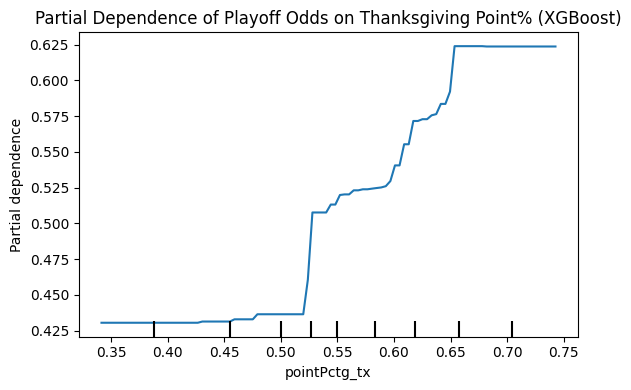

In [105]:
from sklearn.inspection import PartialDependenceDisplay
import matplotlib.pyplot as plt

feature_name = "pointPctg_tx"

fig, ax = plt.subplots(figsize=(6, 4))
PartialDependenceDisplay.from_estimator(
    xgb_best,
    X_train,
    [feature_name],
    ax=ax
)

ax.set_title("Partial Dependence of Playoff Odds on Thanksgiving Point% (XGBoost)")
ax.set_xlabel("Thanksgiving Point% (pointPctg_tx)")
ax.set_ylabel("Predicted Playoff Probability")
plt.tight_layout()
plt.show()


### SHAP: summary + interaction with gaa_x_sv

In [106]:
import shap

# For tree models, this is efficient
explainer = shap.TreeExplainer(xgb_best)
shap_values = explainer.shap_values(X_train)


#### Global importance (summary plot)
This gives you the ranked feature importance and whether higher values push playoff odds up or down.

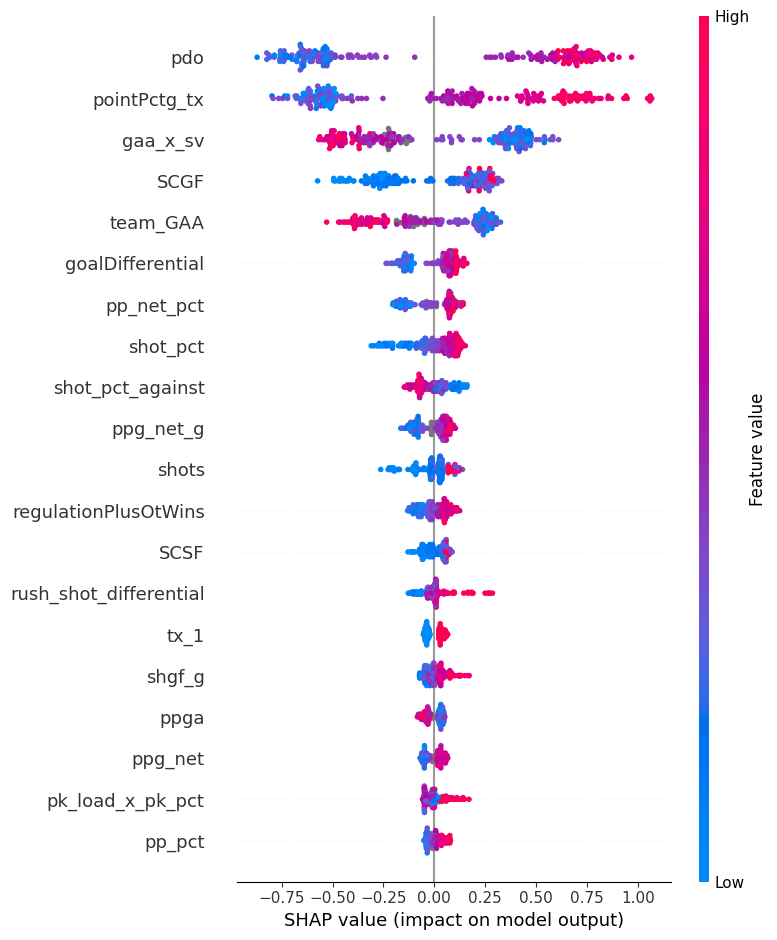

In [107]:
# Summary plot of feature importance & direction
shap.summary_plot(shap_values, X_train, max_display=20)

#### Interaction: pointPctg_tx vs gaa_x_sv

This gives a scatter showing:

- x-axis = pointPctg_tx

- y-axis = SHAP value (impact on playoff odds)

- color = values of gaa_x_sv

That’s your “how much does goaltending quality amplify the effect of being good by Thanksgiving?” graphic.

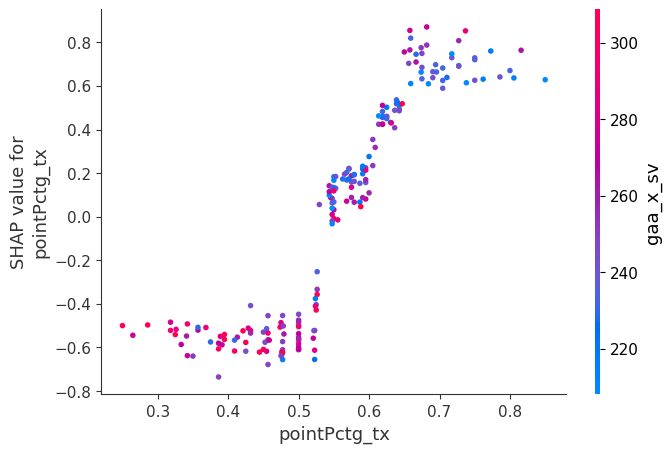

In [108]:
# Dependence plot with interaction highlighting
shap.dependence_plot(
    "pointPctg_tx",
    shap_values,
    X_train,
    interaction_index="gaa_x_sv"
)


#### 2025–26 sheet + bubble team risk index + table

In [109]:
# prediction_2026 = playoff_odds.copy()

# export_path = r"C:\Users\kjchr\Desktop\hockey\new_hockey_env\API data\Thanksgiving Model\thanksgiving_prediction_model\playoff_odds_2025_26_2.csv"
# prediction_2026.to_csv(export_path, index=False)



#### 4.2 Bubble Team Risk Index

Let’s flag “bubble” as:

Consensus odds between 0.35 and 0.75, and/or

RF and XGB disagree strongly (≥ 0.20 absolute difference)

In [ ]:
playoff_odds["model_disagreement"] = (
    (playoff_odds["rf_prob"] - playoff_odds["xgb_prob"]).abs()
)

playoff_odds["is_bubble"] = (
    (playoff_odds["thanksgiving_playoff_odds"].between(0.35, 0.75))
    | (playoff_odds["model_disagreement"] >= 0.20)
)

# Bubble team “risk index” – higher = more chaotic
playoff_odds["bubble_risk_index"] = (
    (0.6 * playoff_odds["model_disagreement"])
    + (0.4 * (0.5 - (playoff_odds["thanksgiving_playoff_odds"] - 0.5).abs()))
)

bubble_teams = playoff_odds[playoff_odds["is_bubble"]].sort_values(
    by="bubble_risk_index",
    ascending=False
)


,team_name,conferenceName,pointPctg_tx,projected_points,rf_prob,xgb_prob,thanksgiving_playoff_odds,rf_class,xgb_class,rf_pick,xgb_pick,final_pick,model_disagreement,is_bubble,bubble_risk_index
17,Utah Mammoth,Western,0.562500,92.0,0.456251,0.636397,0.564339,0,1,Miss,Make,Make Playoffs,0.180146,True,0.282352
10,Los Angeles Kings,Western,0.608696,100.0,0.446635,0.587387,0.531086,0,1,Miss,Make,Make Playoffs,0.140753,True,0.272017
12,New York Islanders,Eastern,0.583333,96.0,0.485030,0.667948,0.594781,0,1,Miss,Make,Make Playoffs,0.182918,True,0.271839
16,Philadelphia Flyers,Eastern,0.613636,101.0,0.482628,0.605605,0.556414,0,1,Miss,Make,Make Playoffs,0.122977,True,0.251221
20,New York Rangers,Eastern,0.520000,85.0,0.521859,0.428203,0.465666,1,0,Make,Miss,Miss Playoffs,0.093656,True,0.242460
21,Florida Panthers,Eastern,0.543478,89.0,0.573104,0.757977,0.684028,1,1,Make,Make,Make Playoffs,0.184873,True,0.237313
18,Detroit Red Wings,Eastern,0.562500,92.0,0.460790,0.514417,0.492966,0,1,Miss,Make,Miss Playoffs,0.053627,True,0.229362
6,Anaheim Ducks,Western,0.630435,103.0,0.579952,0.738397,0.675019,1,1,Make,Make,Make Playoffs,0.158445,True,0.225059
11,Washington Capitals,Eastern,0.583333,96.0,0.520431,0.593604,0.564335,1,1,Make,Make,Make Playoffs,0.073172,True,0.218169
4,Carolina Hurricanes,Eastern,0.652174,107.0,0.498875,0.542572,0.525093,0,1,Miss,Make,Make Playoffs,0.043696,True,0.216181


In [127]:

bubble_teams.sort_values(by=['conferenceName', 'bubble_risk_index'], ascending=False)


,team_name,conferenceName,pointPctg_tx,projected_points,rf_prob,xgb_prob,thanksgiving_playoff_odds,rf_class,xgb_class,rf_pick,xgb_pick,final_pick,model_disagreement,is_bubble,bubble_risk_index
17,Utah Mammoth,Western,0.562500,92.0,0.456251,0.636397,0.564339,0,1,Miss,Make,Make Playoffs,0.180146,True,0.282352
10,Los Angeles Kings,Western,0.608696,100.0,0.446635,0.587387,0.531086,0,1,Miss,Make,Make Playoffs,0.140753,True,0.272017
6,Anaheim Ducks,Western,0.630435,103.0,0.579952,0.738397,0.675019,1,1,Make,Make,Make Playoffs,0.158445,True,0.225059
7,Vegas Golden Knights,Western,0.608696,100.0,0.470430,0.495981,0.485761,0,0,Miss,Miss,Miss Playoffs,0.025551,True,0.209635
23,San Jose Sharks,Western,0.520833,85.0,0.441413,0.369799,0.398445,0,0,Miss,Miss,Miss Playoffs,0.071613,True,0.202346
12,New York Islanders,Eastern,0.583333,96.0,0.485030,0.667948,0.594781,0,1,Miss,Make,Make Playoffs,0.182918,True,0.271839
16,Philadelphia Flyers,Eastern,0.613636,101.0,0.482628,0.605605,0.556414,0,1,Miss,Make,Make Playoffs,0.122977,True,0.251221
20,New York Rangers,Eastern,0.520000,85.0,0.521859,0.428203,0.465666,1,0,Make,Miss,Miss Playoffs,0.093656,True,0.242460
21,Florida Panthers,Eastern,0.543478,89.0,0.573104,0.757977,0.684028,1,1,Make,Make,Make Playoffs,0.184873,True,0.237313
18,Detroit Red Wings,Eastern,0.562500,92.0,0.460790,0.514417,0.492966,0,1,Miss,Make,Miss Playoffs,0.053627,True,0.229362


In [111]:
# prediction_2026 = playoff_odds.copy()

# export_path = r"C:\Users\kjchr\Desktop\hockey\new_hockey_env\API data\Thanksgiving Model\thanksgiving_prediction_model\playoff_odds_2025_26_2.csv"
# prediction_2026.to_csv(export_path, index=False)



In [112]:
article_table = playoff_odds[[
    "team_name",
    "conferenceName",
    "pointPctg_tx",
    "projected_points",
    "thanksgiving_playoff_odds",
    "rf_prob",
    "xgb_prob",
    "final_pick",
    "is_bubble"
]].copy()

# Nice formatting
article_table["thanksgiving_playoff_odds"] = (
    article_table["thanksgiving_playoff_odds"] * 100
).round(1)

article_table["rf_prob"]  = (article_table["rf_prob"]  * 100).round(1)
article_table["xgb_prob"] = (article_table["xgb_prob"] * 100).round(1)

article_table = article_table.sort_values(
    by=["conferenceName", "thanksgiving_playoff_odds"],
    ascending=[True, False]
)

article_table


,team_name,conferenceName,pointPctg_tx,projected_points,thanksgiving_playoff_odds,rf_prob,xgb_prob,final_pick,is_bubble
14,Pittsburgh Penguins,Eastern,0.613636,101.0,84.5,72.4,92.599998,Make Playoffs,True
3,Tampa Bay Lightning,Eastern,0.652174,107.0,83.7,75.5,89.199997,Make Playoffs,False
2,New Jersey Devils,Eastern,0.673913,111.0,80.2,68.5,87.900002,Make Playoffs,False
21,Florida Panthers,Eastern,0.543478,89.0,68.4,57.3,75.800003,Make Playoffs,True
12,New York Islanders,Eastern,0.583333,96.0,59.5,48.5,66.800003,Make Playoffs,True
11,Washington Capitals,Eastern,0.583333,96.0,56.4,52.0,59.400002,Make Playoffs,True
16,Philadelphia Flyers,Eastern,0.613636,101.0,55.6,48.3,60.599998,Make Playoffs,True
4,Carolina Hurricanes,Eastern,0.652174,107.0,52.5,49.9,54.299999,Make Playoffs,True
15,Montréal Canadiens,Eastern,0.613636,101.0,50.4,51.0,50.000000,Make Playoffs,True
18,Detroit Red Wings,Eastern,0.562500,92.0,49.3,46.1,51.400002,Miss Playoffs,True


## SHAP for Teams

In [113]:
explainer = shap.TreeExplainer(xgb_best)
shap_values = explainer.shap_values(X_test_final)

shap_df = pd.DataFrame(
    shap_values,
    columns=X_test_final.columns,
    index=X_test_final.index
)


In [114]:


# 1. Create explainer (fast, exact for XGB)
explainer = shap.TreeExplainer(xgb_best)

# 2. Compute SHAP values for your test teams
shap_values = explainer.shap_values(X_test_final)

# shap_values shape = (num_teams, num_features)

# 3. Build dataframe
shap_df = pd.DataFrame(
    shap_values,
    columns=X_test_final.columns,
    index=X_test_final.index
)

# 4. Attach team names
team_shap = test_df[['team_name', 'tri_code']].join(shap_df)

team_shap.head()


,team_name,tri_code,pointPctg_tx,goalDifferential,gf_g,ga_g,regulationPlusOtWins,pp_gf,pp_net_pct,pp_pct,ppg_net,ppg_net_g,pp_opp,pp_opp_g,pk_net_pct,pk_pct,pkg_net,pkg_net_g,ppga,shgf,shgf_g,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,SCF,SCSF,SCGF,SCA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,SOS_tx,conf_playoff_chance_baseline,pt_pct_x_sos,gaa_x_sv,gd_x_rushdiff,pk_opp_g,pk_load_x_pk_pct,tx_-1,tx_0,tx_1,conf_Eastern,conf_Western,rank_tier1_elite,rank_tier2_strong,rank_tier3_bubble,rank_tier4_bottom
0,Colorado Avalanche,COL,0.623959,0.109760,-0.000107,0.032406,0.047619,-0.068899,-0.170244,-0.031431,-0.034157,0.031079,-0.023403,-0.009376,0.016869,0.007918,0.025809,0.004669,0.032526,-0.012557,-0.024325,0.002849,0.002084,0.047994,0.026556,0.181405,0.017228,0.043674,0.198524,0.012874,0.103011,0.060022,-0.057342,0.097266,0.030642,0.593431,-0.050099,0.000139,0.018647,0.280079,0.000093,-0.008158,0.029537,0.006683,0.0,0.025761,0.0,0.0,0.032132,0.016807,0.0,0.011889
1,Dallas Stars,DAL,0.622487,0.096143,0.002272,0.007733,0.063645,-0.064828,0.080331,0.033779,-0.046173,0.046394,-0.019643,0.007861,-0.018776,0.001351,0.028666,-0.009553,0.031387,-0.018005,-0.033017,0.000277,0.002084,0.007339,-0.017959,0.229153,0.017228,0.052553,0.245445,0.015233,0.083141,0.082570,-0.059045,-0.038177,-0.006992,0.456349,-0.047714,0.000139,0.026685,0.330544,-0.049855,-0.008989,-0.016312,0.012072,0.0,0.027257,0.0,0.0,0.047961,0.017694,0.0,0.010436
2,New Jersey Devils,NJD,0.684028,0.058440,0.008222,-0.012882,0.091358,-0.066577,0.089892,0.039893,-0.041215,0.049284,-0.020789,-0.035082,0.032417,0.002729,0.028709,0.008781,0.040370,-0.001056,0.030902,0.004720,0.001878,0.003826,-0.070153,-0.125908,0.013656,0.049131,0.205594,0.012087,0.123773,0.067625,-0.056741,0.100628,0.026201,0.735045,-0.034352,0.000139,0.032960,-0.205557,0.007027,-0.018420,-0.014890,0.011178,0.0,0.034910,0.0,0.0,0.033149,0.016441,0.0,0.009257
3,Tampa Bay Lightning,TBL,0.648031,0.103129,-0.011046,0.037414,0.042191,-0.067475,-0.167553,-0.032124,-0.038450,-0.087507,-0.023602,0.007928,0.016741,0.007714,0.029190,0.002676,0.032288,-0.015498,0.003490,0.002531,0.002084,0.001961,0.004241,0.203082,0.017713,0.050804,0.200430,0.015584,-0.062131,0.071832,-0.057282,0.099196,0.027534,0.613847,-0.046821,0.000139,0.025361,0.317457,-0.015783,-0.004566,0.030222,0.007146,0.0,0.021532,0.0,0.0,0.041148,0.015723,0.0,0.008041
4,Carolina Hurricanes,CAR,0.838904,0.071359,0.026791,-0.014927,0.091957,-0.058976,-0.137412,-0.036052,-0.064448,-0.107902,0.009888,0.005680,0.001361,-0.003964,0.025870,-0.004708,0.019575,-0.015430,0.074716,0.001064,0.001977,0.139610,-0.041454,-0.071800,0.009520,0.071348,0.281392,0.017612,-0.165436,0.078799,-0.065148,-0.061970,-0.012280,-0.619732,0.016661,-0.000243,0.019108,-0.213419,0.021003,-0.021936,-0.026651,-0.014378,0.0,-0.026079,0.0,0.0,0.076464,0.015964,0.0,0.003232


In [115]:
def biggest_sinker(row):
    return row[row < 0].idxmin()   # most negative effect

sinkers = shap_df.apply(biggest_sinker, axis=1)
sinkers = pd.DataFrame({
    'team': test_df['team_name'],
    'biggest_sinker': sinkers
})


In [116]:
def biggest_sinker_value(row):
    return row.min()

sinker_values = shap_df.apply(biggest_sinker_value, axis=1)

sinkers['impact'] = sinker_values
sinkers.sort_values('impact')


,team,biggest_sinker,impact
7,Vegas Golden Knights,pdo,-0.695921
13,Boston Bruins,pdo,-0.685504
20,New York Rangers,pdo,-0.682504
16,Philadelphia Flyers,pdo,-0.656235
19,Columbus Blue Jackets,pdo,-0.652768
10,Los Angeles Kings,pdo,-0.650802
30,Calgary Flames,pdo,-0.627361
23,San Jose Sharks,pointPctg_tx,-0.620733
4,Carolina Hurricanes,pdo,-0.619732
31,Nashville Predators,pdo,-0.594526


In [117]:
shap_df.head()

,pointPctg_tx,goalDifferential,gf_g,ga_g,regulationPlusOtWins,pp_gf,pp_net_pct,pp_pct,ppg_net,ppg_net_g,pp_opp,pp_opp_g,pk_net_pct,pk_pct,pkg_net,pkg_net_g,ppga,shgf,shgf_g,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,SCF,SCSF,SCGF,SCA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,SOS_tx,conf_playoff_chance_baseline,pt_pct_x_sos,gaa_x_sv,gd_x_rushdiff,pk_opp_g,pk_load_x_pk_pct,tx_-1,tx_0,tx_1,conf_Eastern,conf_Western,rank_tier1_elite,rank_tier2_strong,rank_tier3_bubble,rank_tier4_bottom
0,0.623959,0.109760,-0.000107,0.032406,0.047619,-0.068899,-0.170244,-0.031431,-0.034157,0.031079,-0.023403,-0.009376,0.016869,0.007918,0.025809,0.004669,0.032526,-0.012557,-0.024325,0.002849,0.002084,0.047994,0.026556,0.181405,0.017228,0.043674,0.198524,0.012874,0.103011,0.060022,-0.057342,0.097266,0.030642,0.593431,-0.050099,0.000139,0.018647,0.280079,0.000093,-0.008158,0.029537,0.006683,0.0,0.025761,0.0,0.0,0.032132,0.016807,0.0,0.011889
1,0.622487,0.096143,0.002272,0.007733,0.063645,-0.064828,0.080331,0.033779,-0.046173,0.046394,-0.019643,0.007861,-0.018776,0.001351,0.028666,-0.009553,0.031387,-0.018005,-0.033017,0.000277,0.002084,0.007339,-0.017959,0.229153,0.017228,0.052553,0.245445,0.015233,0.083141,0.082570,-0.059045,-0.038177,-0.006992,0.456349,-0.047714,0.000139,0.026685,0.330544,-0.049855,-0.008989,-0.016312,0.012072,0.0,0.027257,0.0,0.0,0.047961,0.017694,0.0,0.010436
2,0.684028,0.058440,0.008222,-0.012882,0.091358,-0.066577,0.089892,0.039893,-0.041215,0.049284,-0.020789,-0.035082,0.032417,0.002729,0.028709,0.008781,0.040370,-0.001056,0.030902,0.004720,0.001878,0.003826,-0.070153,-0.125908,0.013656,0.049131,0.205594,0.012087,0.123773,0.067625,-0.056741,0.100628,0.026201,0.735045,-0.034352,0.000139,0.032960,-0.205557,0.007027,-0.018420,-0.014890,0.011178,0.0,0.034910,0.0,0.0,0.033149,0.016441,0.0,0.009257
3,0.648031,0.103129,-0.011046,0.037414,0.042191,-0.067475,-0.167553,-0.032124,-0.038450,-0.087507,-0.023602,0.007928,0.016741,0.007714,0.029190,0.002676,0.032288,-0.015498,0.003490,0.002531,0.002084,0.001961,0.004241,0.203082,0.017713,0.050804,0.200430,0.015584,-0.062131,0.071832,-0.057282,0.099196,0.027534,0.613847,-0.046821,0.000139,0.025361,0.317457,-0.015783,-0.004566,0.030222,0.007146,0.0,0.021532,0.0,0.0,0.041148,0.015723,0.0,0.008041
4,0.838904,0.071359,0.026791,-0.014927,0.091957,-0.058976,-0.137412,-0.036052,-0.064448,-0.107902,0.009888,0.005680,0.001361,-0.003964,0.025870,-0.004708,0.019575,-0.015430,0.074716,0.001064,0.001977,0.139610,-0.041454,-0.071800,0.009520,0.071348,0.281392,0.017612,-0.165436,0.078799,-0.065148,-0.061970,-0.012280,-0.619732,0.016661,-0.000243,0.019108,-0.213419,0.021003,-0.021936,-0.026651,-0.014378,0.0,-0.026079,0.0,0.0,0.076464,0.015964,0.0,0.003232


In [129]:
# Combine SHAP with identifying info
sinker_df = test_df[['team_name', 'tri_code', 'season_id']].copy()
sinker_df.reset_index(drop=True, inplace=True)

# Get SHAP values for predictions (align to test_df index)
shap_aligned = shap_df.reset_index(drop=True)

# Find the top 3 negative SHAP contributors for each row
top_sinks = []
for i in range(len(shap_aligned)):
    
    row = shap_aligned.iloc[i]
    
    # Sort the row's SHAP values from most negative to least
    sorted_row = row.sort_values(ascending=True)

    # Extract top 3 lowest
    biggest = sorted_row.index[0], sorted_row.iloc[0]
    second  = sorted_row.index[1], sorted_row.iloc[1]
    third   = sorted_row.index[2], sorted_row.iloc[2]

    top_sinks.append([biggest, second, third])

# Convert to columns
sinker_df["biggest_sinker"] = [f"{f} ({v:.3f})" for f, v in [t[0] for t in top_sinks]]
sinker_df["second_biggest_sinker"] = [f"{f} ({v:.3f})" for f, v in [t[1] for t in top_sinks]]
sinker_df["third_biggest_sinker"] = [f"{f} ({v:.3f})" for f, v in [t[2] for t in top_sinks]]


sinker_df = sinker_df.merge(playoff_odds[['team_name', 'final_pick']], on='team_name', how = 'inner')
# sinker_df[sinker_df['final_pick']=='Miss Playoffs']
sinker_df

,team_name,tri_code,season_id,biggest_sinker,second_biggest_sinker,third_biggest_sinker,final_pick
0,Colorado Avalanche,COL,20252026,pp_net_pct (-0.170),pp_gf (-0.069),shots_against (-0.057),Make Playoffs
1,Dallas Stars,DAL,20252026,pp_gf (-0.065),shots_against (-0.059),gd_x_rushdiff (-0.050),Make Playoffs
2,New Jersey Devils,NJD,20252026,gaa_x_sv (-0.206),team_GAA (-0.126),team_savePct (-0.070),Make Playoffs
3,Tampa Bay Lightning,TBL,20252026,pp_net_pct (-0.168),ppg_net_g (-0.088),pp_gf (-0.067),Make Playoffs
4,Carolina Hurricanes,CAR,20252026,pdo (-0.620),gaa_x_sv (-0.213),shot_pct (-0.165),Make Playoffs
5,Minnesota Wild,MIN,20252026,pp_gf (-0.063),shots_against (-0.062),ppg_net (-0.047),Make Playoffs
6,Anaheim Ducks,ANA,20252026,gaa_x_sv (-0.446),team_GAA (-0.340),team_savePct (-0.079),Make Playoffs
7,Vegas Golden Knights,VGK,20252026,pdo (-0.696),shot_pct (-0.219),ppg_net (-0.071),Miss Playoffs
8,Ottawa Senators,OTT,20252026,pdo (-0.577),gaa_x_sv (-0.513),team_GAA (-0.387),Miss Playoffs
9,Seattle Kraken,SEA,20252026,pp_gf (-0.071),shots_against (-0.057),SOS_tx (-0.048),Make Playoffs


## What If PK Load Simulation

“If PK load is reduced by 10/20/30%, how much would the playoff probability change?”

In [119]:
def simulate_pk_load_change(test_df, model, X_columns, pct_list=[0.10, 0.20, 0.30]):
    """
    Simulates playoff probability change from reducing PK load.
    Automatically rebuilds ALL model features (interactions + dummies).
    """

    results = []

    for pct in pct_list:

        df_sim = test_df.copy()

        # -------------------------------------
        # 1. Apply PK load reduction
        # -------------------------------------
        df_sim["pk_opp_g"] = df_sim["pk_opp_g"] * (1 - pct)
        df_sim["pk_load_x_pk_pct"] = df_sim["pk_opp_g"] * df_sim["pk_pct"]

        # -------------------------------------
        # 2. Rebuild ALL derived model features
        # -------------------------------------

        # Interaction features
        df_sim["pt_pct_x_sos"] = df_sim["pointPctg_tx"] * df_sim["SOS_tx"]
        df_sim["gaa_x_sv"] = df_sim["team_GAA"] * df_sim["sv_pct"]
        df_sim["gd_x_rushdiff"] = df_sim["goalDifferential"] * df_sim["rush_shot_differential"]

        # Dummies (identical to training)
        streak_d = pd.get_dummies(df_sim["thanksgiving_streak"], prefix="tx")
        conf_d   = pd.get_dummies(df_sim["conferenceName"], prefix="conf")
        rank_d   = pd.get_dummies(df_sim["rank_bucket"], prefix="rank")

        # Base features (same block as training)
        X_sim = df_sim[[ 
            'pointPctg_tx', 'goalDifferential', 'gf_g', 'ga_g',
            'regulationPlusOtWins', 'pp_gf', 'pp_net_pct', 'pp_pct',
            'ppg_net', 'ppg_net_g', 'pp_opp', 'pp_opp_g',
            'pk_net_pct', 'pk_pct', 'pkg_net', 'pkg_net_g',
            'ppga', 'shgf', 'shgf_g',
            'rush_shots_for', 'rush_shots_against', 'rush_shot_differential',
            'team_savePct', 'team_GAA', 'SCF', 'SCSF', 'SCGF', 'SCA',
            'shot_pct', 'shots', 'shots_against', 'shot_pct_against', 'sv_pct',
            'pdo', 'SOS_tx', 'conf_playoff_chance_baseline',
            'pt_pct_x_sos', 'gaa_x_sv', 'gd_x_rushdiff',
            'pk_opp_g', 'pk_load_x_pk_pct'
        ]]

        # Add dummy variables
        X_sim = pd.concat([X_sim, streak_d, conf_d, rank_d], axis=1)

        # Align to training columns
        X_sim = X_sim.reindex(columns=X_columns, fill_value=0)

        # -------------------------------------
        # 3. Get playoff probabilities
        # -------------------------------------
        df_sim["sim_prob"] = model.predict_proba(X_sim)[:, 1]
        df_sim["pk_reduction"] = pct

        results.append(df_sim[["team_name", "pk_reduction", "sim_prob"]])

    return pd.concat(results, ignore_index=True)


In [120]:
test_df[test_df['team_name']=='Boston Bruins']

,season_id,tri_code,team_id,team_name,conferenceName,conferenceSequence,gamesPlayed,points,winPctg,pointPctg,regulationPlusOtWins,goalDifferential,goalFor,goalAgainst,homeGamesPlayed,homeWins,roadGamesPlayed,roadWins,l10GoalDifferential,streakCount,home_win_pctg,road_win_pctg,gf_g,ga_g,projected_points,thanksgiving_date,SOS,Remaining_SOS,games_played_pp,pp_gf,shGoalsAgainst,pp_opp,ppg_net,ppTimeOnIce,pp_pct,pp_net_pct,ppg_g,pp_opp_g,shGoalsAgainstPerGame,ppg_net_g,ppTimeOnIcePerGame,games_played_pk,ppga,shgf,timesShorthanded,pkg_net,pkTimeOnIce,pk_pct,pk_net_pct,ppga_g,shgf_g,timesShorthandedPerGame,pkg_net_g,pkTimeOnIcePerGame,pointsPct,rush_shots_for,rush_shots_against,rush_shot_differential,team_savePct,team_GAA,shot_pct,shots,shots_against,shot_pct_against,sv_pct,pdo,SCF,SCSF,SCGF,SCA,run_date,tx_playoff_spot,conference_team_count,conf_playoff_chance_baseline,thanksgiving_streak,rank_bucket,pointPctg_tx,SOS_tx,pk_opp_g,pt_pct_x_sos,gaa_x_sv,gd_x_rushdiff,pk_load_x_pk_pct,predicted_status,playoff_prob,rf_prob,xgb_prob,rf_class,xgb_class,thanksgiving_playoff_odds
13,20252026,BOS,6,Boston Bruins,Eastern,7,25,28,0.56,0.56,13,0,78,78,12,8,13,6,2,1,0.666667,0.461538,3.12,3.12,92.0,2025-11-27,0.482961,0.448022,25,20,4,79,16,7600.0,25.32,20.25,0.8,3.16,0.16,0.64,304.0,25,16,1,98,-15,9859.0,83.67,84.69,0.64,0.04,3.92,-0.6,394.36,0.56,2604,2599,5,0.9025,2.947877,5.89,8290,8399,6.61,93.39,99.28,16457,3944,383,31700,2025-11-30,1,16,0.5,1,tier3_bubble,0.56,0.482961,3.92,0.270458,275.302219,0,327.9864,0,0.340566,0.439955,0.340566,0,0,0.380322


In [121]:
# pk_sim_results = simulate_pk_load_change(
#     test_df=test_df,
#     model=rf_best,
#     X_columns=X.columns,
#     pct_list=[0.10, 0.20, 0.30]
# )

# pk_sim_results.head()

def simulate_pk_load_change_wide(test_df, model, X_columns, pct_list=[0.10, 0.20, 0.30]):
    """
    Returns a wide-format table:
    team_name | baseline_prob | pk_red_10 | pk_red_20 | pk_red_30
    """

    results = test_df[["team_name"]].copy()

    # -----------------------------
    # Baseline probability
    # -----------------------------
    X_base = build_model_matrix(test_df, X_columns)
    baseline_probs = model.predict_proba(X_base)[:, 1]

    results["baseline_prob"] = baseline_probs

    # -----------------------------
    # Simulations for each % reduction
    # -----------------------------
    for pct in pct_list:
        df_sim = test_df.copy()

        # reduce PK load
        df_sim["pk_opp_g"] = df_sim["pk_opp_g"] * (1 - pct)
        df_sim["pk_load_x_pk_pct"] = df_sim["pk_opp_g"] * df_sim["pk_pct"]

        # rebuild model matrix
        X_sim = build_model_matrix(df_sim, X_columns)

        # playoff probability
        sim_probs = model.predict_proba(X_sim)[:, 1]

        # add column
        col_name = f"pk_red_{int(pct*100)}"
        results[col_name] = sim_probs
        
        results[col_name + "_status"] = (sim_probs >= 0.5).astype(int)

    return results



In [122]:
pk_sim_results = simulate_pk_load_change_wide(
    test_df=test_df,
    model=rf_best,
    X_columns=X.columns,
    pct_list=[0.10, 0.20, 0.30]
)

pk_sim_results


NameError: name 'build_model_matrix' is not defined

In [ ]:
def build_model_matrix(df, X_columns):
    """
    Rebuild the full feature matrix (numerics + interactions + dummies)
    exactly like you did for training, then align to X_columns.
    """
    df = df.copy()

    # Ensure categoricals have the same category set
    df["thanksgiving_streak"] = pd.Categorical(
        df["thanksgiving_streak"].astype(str),
        categories=streak_categories
    )
    df["rank_bucket"] = pd.Categorical(
        df["rank_bucket"],
        categories=rank_categories
    )
    df["conferenceName"] = pd.Categorical(
        df["conferenceName"],
        categories=conference_categories
    )

    # ===== Interaction features (same as training) =====
    df["pt_pct_x_sos"] = df["pointPctg_tx"] * df["SOS_tx"]
    df["gaa_x_sv"] = df["team_GAA"] * df["sv_pct"]
    df["gd_x_rushdiff"] = df["goalDifferential"] * df["rush_shot_differential"]
    df["pk_load_x_pk_pct"] = df["pk_opp_g"] * df["pk_pct"]

    # ===== Dummies (same as training) =====
    streak_d = pd.get_dummies(df["thanksgiving_streak"], prefix="tx")
    conf_d   = pd.get_dummies(df["conferenceName"], prefix="conf")
    rank_d   = pd.get_dummies(df["rank_bucket"], prefix="rank")

    # ===== Base numeric features (same block as in training) =====
    X_sim = df[[ 
        'pointPctg_tx', 'goalDifferential', 'gf_g', 'ga_g',
        'regulationPlusOtWins', 'pp_gf', 'pp_net_pct', 'pp_pct',
        'ppg_net', 'ppg_net_g', 'pp_opp', 'pp_opp_g',
        'pk_net_pct', 'pk_pct', 'pkg_net', 'pkg_net_g',
        'ppga', 'shgf', 'shgf_g',
        'rush_shots_for', 'rush_shots_against', 'rush_shot_differential',
        'team_savePct', 'team_GAA', 'SCF', 'SCSF', 'SCGF', 'SCA',
        'shot_pct', 'shots', 'shots_against', 'shot_pct_against', 'sv_pct',
        'pdo', 'SOS_tx', 'conf_playoff_chance_baseline',
        'pt_pct_x_sos', 'gaa_x_sv', 'gd_x_rushdiff',
        'pk_opp_g', 'pk_load_x_pk_pct'
    ]]

    # Add dummy columns
    X_sim = pd.concat([X_sim, streak_d, conf_d, rank_d], axis=1)

    # Align with training feature set
    X_sim = X_sim.reindex(columns=X_columns, fill_value=0)

    return X_sim


In [ ]:
def build_scenario_table(test_df, model, X_columns):
    """
    Build a scenario table of playoff probabilities under different
    hypothetical improvements.
    """
    scenario_rows = []

    # 1️⃣ Baseline
    base_df = test_df.copy()
    X_base = build_model_matrix(base_df, X_columns)
    base_probs = model.predict_proba(X_base)[:, 1]
    base_pred = (base_probs >= 0.5).astype(int)

    base_df["scenario"] = "Baseline"
    base_df["playoff_prob"] = base_probs
    base_df["predicted_status"] = base_pred
    scenario_rows.append(
        base_df[["team_name", "conferenceName", "scenario", "playoff_prob", "predicted_status"]]
    )

    # 2️⃣ PK load -20%
    pk_df = test_df.copy()
    pk_df["pk_opp_g"] = pk_df["pk_opp_g"] * 0.8
    pk_df["scenario"] = "PK load -20%"

    X_pk = build_model_matrix(pk_df, X_columns)
    pk_probs = model.predict_proba(X_pk)[:, 1]
    pk_pred = (pk_probs >= 0.5).astype(int)

    pk_df["playoff_prob"] = pk_probs
    pk_df["predicted_status"] = pk_pred
    scenario_rows.append(
        pk_df[["team_name", "conferenceName", "scenario", "playoff_prob", "predicted_status"]]
    )

    # 3️⃣ SV% +0.003  (cap at 0.99 to avoid silly values)
    sv_df = test_df.copy()
    sv_df["sv_pct"] = (sv_df["sv_pct"] + 0.003).clip(upper=0.99)
    # If team_savePct mirrors sv_pct, sync it
    sv_df["team_savePct"] = sv_df["sv_pct"]

    # OPTIONAL: recompute PDO if you want consistency:
    # sv_df["pdo"] = 100 * (sv_df["shot_pct"] + sv_df["sv_pct"])

    sv_df["scenario"] = "SV% +0.003"

    X_sv = build_model_matrix(sv_df, X_columns)
    sv_probs = model.predict_proba(X_sv)[:, 1]
    sv_pred = (sv_probs >= 0.5).astype(int)

    sv_df["playoff_prob"] = sv_probs
    sv_df["predicted_status"] = sv_pred
    scenario_rows.append(
        sv_df[["team_name", "conferenceName", "scenario", "playoff_prob", "predicted_status"]]
    )

    # 4️⃣ +2 Reg/OT Wins
    rw_df = test_df.copy()
    rw_df["regulationPlusOtWins"] = rw_df["regulationPlusOtWins"] + 2
    rw_df["scenario"] = "+2 Reg/OT wins"

    X_rw = build_model_matrix(rw_df, X_columns)
    rw_probs = model.predict_proba(X_rw)[:, 1]
    rw_pred = (rw_probs >= 0.5).astype(int)

    rw_df["playoff_prob"] = rw_probs
    rw_df["predicted_status"] = rw_pred
    scenario_rows.append(
        rw_df[["team_name", "conferenceName", "scenario", "playoff_prob", "predicted_status"]]
    )

    # 5️⃣ Combo: PK -20% + SV% +0.003 + +2 RW
    combo_df = test_df.copy()
    combo_df["pk_opp_g"] = combo_df["pk_opp_g"] * 0.8
    combo_df["sv_pct"] = (combo_df["sv_pct"] + 0.003).clip(upper=0.99)
    combo_df["team_savePct"] = combo_df["sv_pct"]
    combo_df["regulationPlusOtWins"] = combo_df["regulationPlusOtWins"] + 2

    # OPTIONAL: recompute PDO again for consistency
    # combo_df["pdo"] = 100 * (combo_df["shot_pct"] + combo_df["sv_pct"])

    combo_df["scenario"] = "PK-20% + SV% +2 RW"

    X_combo = build_model_matrix(combo_df, X_columns)
    combo_probs = model.predict_proba(X_combo)[:, 1]
    combo_pred = (combo_probs >= 0.5).astype(int)

    combo_df["playoff_prob"] = combo_probs
    combo_df["predicted_status"] = combo_pred
    scenario_rows.append(
        combo_df[["team_name", "conferenceName", "scenario", "playoff_prob", "predicted_status"]]
    )

    # 🔚 Combine all scenarios
    scenarios = pd.concat(scenario_rows, ignore_index=True)

    # Map 0/1 to labels
    scenarios["playoff_prediction"] = scenarios["predicted_status"].map(
        {1: "Make Playoffs", 0: "Miss Playoffs"}
    )

    # Sort nicely
    scenarios = scenarios.sort_values(
        by=["conferenceName", "team_name", "scenario"]
    )

    return scenarios


In [ ]:
scenario_table = build_scenario_table(
    test_df=test_df,
    model=rf_best,          # or xgb_best if you prefer that one
    X_columns=X.columns     # from your training pipeline
)

scenario_table.head()
#boston has been shorthanded 98 times.

In [ ]:
scenario_pivot = (
    scenario_table
    .pivot_table(
        index=["conferenceName", "team_name"],
        columns="scenario",
        values="playoff_prob"
    )
    .round(3)
    .reset_index()
)

scenario_pivot


In [130]:

con.close()
print("DuckDB connection closed.")

DuckDB connection closed.
